In [2]:
import numpy as np
from pyscf.dft import numint
import scipy
from functools import reduce
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator
import re
from pyscf import tools
import pandas as pd
import h5py
from matplotlib.patches import Patch 
from scipy.stats import norm
import seaborn

# Settings
plt.rc('font', family='Times New Roman', size=14)
plt.rcParams['mathtext.fontset'] = 'custom'

plt.rcParams['mathtext.it'] = 'STIXGeneral:italic'
plt.rcParams['mathtext.rm'] = 'STIXGeneral:bold'
plt.rcParams['mathtext.tt'] = 'STIXGeneral'
plt.rcParams['mathtext.bf'] = 'STIXGeneral:bold:italic'
plt.rcParams['mathtext.cal'] = 'STIXGeneral'
plt.rcParams['mathtext.sf'] = 'STIXGeneral'

plt.rcParams['lines.linewidth'] = 1
plt.rcParams['axes.linewidth'] = 1


In [3]:
path = 'TADF_all.xlsx'

def read_xlsx(path,keys,nums):
    f = pd.ExcelFile(path)
    data = f.parse(keys)
    ref = np.array(data.iloc[2:,1][:nums])
    #print(ref)
    b3lyp_tda = np.array(data.iloc[2:,2][:nums])
    b3lyp_tddft = np.array(data.iloc[2:,3][:nums])
    b3lyp_usftddft = np.array(data.iloc[2:,4][:nums])
    b3lyp_alda0_usf = np.array(data.iloc[2:,5][:nums])
    b3lyp_alda0_xsf = np.array(data.iloc[2:,6][:nums])
    b3lyp_mc_usf = np.array(data.iloc[2:,7][:nums])
    b3lyp_mc_xsf = np.array(data.iloc[2:,8][:nums])

    pbe0_tda = np.array(data.iloc[2:,10][:nums])
    pbe0_tddft = np.array(data.iloc[2:,11][:nums])
    pbe0_usftddft = np.array(data.iloc[2:,12][:nums])
    pbe0_alda0_usf = np.array(data.iloc[2:,13][:nums])
    pbe0_alda0_xsf = np.array(data.iloc[2:,14][:nums])
    pbe0_mc_usf = np.array(data.iloc[2:,15][:nums])
    pbe0_mc_xsf = np.array(data.iloc[2:,16][:nums])

    bhhlyp_tda = np.array(data.iloc[2:,18][:nums])
    bhhlyp_tddft = np.array(data.iloc[2:,19][:nums])
    bhhlyp_usftddft = np.array(data.iloc[2:,20][:nums])
    bhhlyp_alda0_usf = np.array(data.iloc[2:,21][:nums])
    bhhlyp_alda0_xsf = np.array(data.iloc[2:,22][:nums])
    bhhlyp_mc_usf = np.array(data.iloc[2:,23][:nums])
    bhhlyp_mc_xsf = np.array(data.iloc[2:,24][:nums])

    cam_tda = np.array(data.iloc[2:,26][:nums])
    cam_tddft = np.array(data.iloc[2:,27][:nums])
    cam_usftddft = np.array(data.iloc[2:,28][:nums])
    cam_alda0_usf = np.array(data.iloc[2:,29][:nums])
    cam_alda0_xsf = np.array(data.iloc[2:,30][:nums])
    cam_mc_usf = np.array(data.iloc[2:,31][:nums])
    cam_mc_xsf = np.array(data.iloc[2:,32][:nums])

    ds2_b3lyp_usftddft = np.array(data.iloc[2:,43][:nums])
    ds2_b3lyp_alda0 = np.array(data.iloc[2:,44][:nums])
    ds2_b3lyp_mc = np.array(data.iloc[2:,45][:nums])
    ds2_pbe0_usftddft = np.array(data.iloc[2:,46][:nums])
    ds2_pbe0_alda0 = np.array(data.iloc[2:,47][:nums])
    ds2_pbe0_mc = np.array(data.iloc[2:,48][:nums])
    ds2_bhhlyp_usftddft = np.array(data.iloc[2:,49][:nums])
    ds2_bhhlyp_alda0 = np.array(data.iloc[2:,50][:nums])
    ds2_bhhlyp_mc = np.array(data.iloc[2:,51][:nums])
    ds2_cam_usftddft = np.array(data.iloc[2:,52][:nums])
    ds2_cam_alda0 = np.array(data.iloc[2:,53][:nums])
    ds2_cam_mc = np.array(data.iloc[2:,54][:nums])
    
    b3lyp_data = [b3lyp_tda,b3lyp_tddft,b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_usftddft,b3lyp_alda0_xsf,b3lyp_mc_xsf]
    pbe0_data = [pbe0_tda,pbe0_tddft,pbe0_alda0_usf,pbe0_mc_usf,pbe0_usftddft,pbe0_alda0_xsf,pbe0_mc_xsf]
    bhhlyp_data = [bhhlyp_tda,bhhlyp_tddft,bhhlyp_alda0_usf,bhhlyp_mc_usf,bhhlyp_usftddft,bhhlyp_alda0_xsf,
                   bhhlyp_mc_xsf]
    cam_data = [cam_tda,cam_tddft,cam_alda0_usf,cam_mc_usf,cam_usftddft,cam_alda0_xsf,cam_mc_xsf]
    ds2_data = [ds2_b3lyp_usftddft,ds2_b3lyp_alda0,ds2_b3lyp_mc,
                ds2_pbe0_usftddft,ds2_pbe0_alda0,ds2_pbe0_mc,
                ds2_bhhlyp_usftddft,ds2_bhhlyp_alda0,ds2_bhhlyp_mc,
                ds2_cam_usftddft,ds2_cam_alda0,ds2_cam_mc]
    return ref,b3lyp_data,pbe0_data,bhhlyp_data,cam_data,ds2_data
    

def calculate_error(data,sign=False): # [ref,usftddft,usf....]
    for i in range(len(data)-1):
        err = data[i+1] - data[0]
        print('MSE  ',np.mean(err))
        print('MAE  ',np.mean(abs(err)))
        print('RMSE ',np.sqrt(np.mean(err**2)))
        print('SE   ',np.std(err,ddof=1)/np.sqrt(len(err)))
        if max(err) >= abs(min(err)):
            print('MAX  ',max(err))
        else:
            print('MAX  ',min(err))
        if sign:
            ref_p = 0 # reference positive
            ref_n = 0 # reference negative
            sf_p = 0 # calculate positive
            sf_n = 0 # calculate negative
            for j in range(len(data[0])):
                if data[0][j]>=0:
                    ref_p += 1
                    if data[i+1][j] >= 0:
                        sf_p += 1
                if data[0][j] < 0:
                    ref_n += 1
                    if data[i+1][j] < 0:
                        sf_n += 1
            print(f'Correct Sign(Positive) {sf_p}/{ref_p} Correct Sign(Negative) {sf_n}/{ref_n}')
        print('/////////////////////')
    return None

def draw_scatter(ref,b3lyp_data,pbe0_data,bhhlyp_data,cam_data,v_max,v_min,names): # data: b3lyp_tda b3lyp_tddft b3lyp_usftddft...
    fig,axs = plt.subplots(4,3,figsize=(12,16)) # 3*4
    x = np.linspace(v_min-0.02,v_max+0.02,100)
    b3lyp_tda,b3lyp_tddft,b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_usftddft,b3lyp_alda0_xsf,b3lyp_mc_xsf = b3lyp_data
    pbe0_tda,pbe0_tddft,pbe0_alda0_usf,pbe0_mc_usf,pbe0_usftddft,pbe0_alda0_xsf,pbe0_mc_xsf = pbe0_data
    bhhlyp_tda,bhhlyp_tddft,bhhlyp_alda0_usf,bhhlyp_mc_usf,bhhlyp_usftddft,bhhlyp_alda0_xsf,bhhlyp_mc_xsf = bhhlyp_data
    cam_tda,cam_tddft,cam_alda0_usf,cam_mc_usf,cam_usftddft,cam_alda0_xsf,cam_mc_xsf = cam_data
    if names == 'nah159_data':
        shift = 0.2
    else:
        shift = 0.1
    axs[0,0].scatter(ref,b3lyp_tda,s=12,label='TDA',color='#9467bd')
    axs[0,0].scatter(ref,b3lyp_tddft,s=12,label='TDDFT',color='#8c564b')
    axs[0,0].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[0,0].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[0,0].set_title('TDA/TD-DFT')
    axs[0,0].plot(x,x,color='black',linewidth=2)
    axs[0,0].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[0,0].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[0,0].set_xlim((v_min-0.02,v_max+0.02))
    axs[0,0].set_ylim((v_min-0.02,v_max+0.02))
    axs[0,0].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[0,0].text(v_min,v_max-shift,'(a) B3LYP')

    axs[0,1].scatter(ref,b3lyp_alda0_usf,s=12,label='USF-TDA(ALDA0)',color='#1f77b4')
    axs[0,1].scatter(ref,b3lyp_mc_usf,s=12,label='USF-TDA(Multicollinear)',color='#ff7f0e')
    axs[0,1].scatter(ref,b3lyp_usftddft,s=12,label='USF-TD-DFT',color='#2ca02c') 
    axs[0,1].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[0,1].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[0,1].set_title('USF-TDA/USF-TD-DFT')
    axs[0,1].plot(x,x,color='black',linewidth=2)
    axs[0,1].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[0,1].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[0,1].set_xlim((v_min-0.02,v_max+0.02))
    axs[0,1].set_ylim((v_min-0.02,v_max+0.02))
    axs[0,1].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[0,1].text(v_min,v_max-shift,'(b) B3LYP')

    axs[0,2].scatter(ref,b3lyp_alda0_xsf,s=12,label='XSF-TDA(ALDA0)',color='#1f77b4')
    axs[0,2].scatter(ref,b3lyp_mc_xsf,s=12,label='XSF-TDA(Multicollinear)',color='#ff7f0e')
    axs[0,2].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[0,2].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[0,2].set_title('XSF-TDA')
    axs[0,2].plot(x,x,color='black',linewidth=2)
    axs[0,2].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[0,2].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[0,2].set_xlim((v_min-0.02,v_max+0.02))
    axs[0,2].set_ylim((v_min-0.02,v_max+0.02))
    axs[0,2].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[0,2].text(v_min,v_max-shift,'(c) B3LYP')

    axs[1,0].scatter(ref,pbe0_tda,s=12,label='TDA',color='#9467bd')
    axs[1,0].scatter(ref,pbe0_tddft,s=12,label='TD-DFT',color='#8c564b')
    axs[1,0].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[1,0].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[1,0].plot(x,x,color='black',linewidth=2)
    axs[1,0].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[1,0].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[1,0].set_xlim((v_min-0.02,v_max+0.02))
    axs[1,0].set_ylim((v_min-0.02,v_max+0.02))
    axs[1,0].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[1,0].text(v_min,v_max-shift,'(d) PBE0')

    axs[1,1].scatter(ref,pbe0_alda0_usf,s=12,label='USF-TDA(ALDA0)',color='#1f77b4')
    axs[1,1].scatter(ref,pbe0_mc_usf,s=12,label='USF-TDA(Multicollinear)',color='#ff7f0e')
    axs[1,1].scatter(ref,pbe0_usftddft,s=12,label='USF-TD-DFT',color='#2ca02c')
    axs[1,1].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[1,1].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[1,1].plot(x,x,color='black',linewidth=2)
    axs[1,1].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[1,1].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[1,1].set_xlim((v_min-0.02,v_max+0.02))
    axs[1,1].set_ylim((v_min-0.02,v_max+0.02))
    axs[1,1].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[1,1].text(v_min,v_max-shift,'(e) PBE0')


    axs[1,2].scatter(ref,pbe0_alda0_xsf,s=12,label='XSF-TDA(ALDA0)',color='#1f77b4')
    axs[1,2].scatter(ref,pbe0_mc_xsf,s=12,label='XSF-TDA(Multicollinear)',color='#ff7f0e')
    axs[1,2].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[1,2].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[1,2].plot(x,x,color='black',linewidth=2)
    axs[1,2].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[1,2].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[1,2].set_xlim((v_min-0.02,v_max+0.02))
    axs[1,2].set_ylim((v_min-0.02,v_max+0.02))
    axs[1,2].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[1,2].text(v_min,v_max-shift,'(f) PBE0')

    axs[2,0].scatter(ref,bhhlyp_tda,s=12,label='TDA',color='#9467bd')
    axs[2,0].scatter(ref,bhhlyp_tddft,s=12,label='TDDFT',color='#8c564b')
    axs[2,0].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[2,0].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[2,0].plot(x,x,color='black',linewidth=2)
    axs[2,0].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[2,0].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[2,0].set_xlim((v_min-0.02,v_max+0.02))
    axs[2,0].set_ylim((v_min-0.02,v_max+0.02))
    axs[2,0].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[2,0].text(v_min,v_max-shift,'(g) BHHLYP')
    
    axs[2,1].scatter(ref,bhhlyp_alda0_usf,s=12,label='USF-TDA(ALDA0)',color='#1f77b4')
    axs[2,1].scatter(ref,bhhlyp_mc_usf,s=12,label='USF-TDA(Multicollinear)',color='#ff7f0e')
    axs[2,1].scatter(ref,bhhlyp_usftddft,s=12,label='USF-TD-TDA',color='#2ca02c')
    axs[2,1].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[2,1].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[2,1].plot(x,x,color='black',linewidth=2)
    axs[2,1].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[2,1].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[2,1].set_xlim((v_min-0.02,v_max+0.02))
    axs[2,1].set_ylim((v_min-0.02,v_max+0.02))
    axs[2,1].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[2,1].text(v_min,v_max-shift,'(h) BHHLYP')
    
    axs[2,2].scatter(ref,bhhlyp_alda0_xsf,s=12,label='XSF-TDA(ALDA0)',color='#1f77b4')
    axs[2,2].scatter(ref,bhhlyp_mc_xsf,s=12,label='XSF-TDA(Multicollinear)',color='#ff7f0e')
    axs[2,2].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[2,2].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[2,2].plot(x,x,color='black',linewidth=2)
    axs[2,2].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[2,2].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[2,2].set_xlim((v_min-0.02,v_max+0.02))
    axs[2,2].set_ylim((v_min-0.02,v_max+0.02))
    axs[2,2].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[2,2].text(v_min,v_max-shift,'(i) BHHLYP')

    axs[3,0].scatter(ref,cam_tda,s=12,label='TDA',color='#9467bd')
    axs[3,0].scatter(ref,cam_tddft,s=12,label='TDDFT',color='#8c564b')
    axs[3,0].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[3,0].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[3,0].plot(x,x,color='black',linewidth=2)
    axs[3,0].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[3,0].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[3,0].set_xlim((v_min-0.02,v_max+0.02))
    axs[3,0].set_ylim((v_min-0.02,v_max+0.02))
    axs[3,0].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[3,0].text(v_min,v_max-shift,'(j) CAM-B3LYP')

    axs[3,1].scatter(ref,cam_alda0_usf,s=12,label='USF-TDA(ALDA0)',color='#1f77b4')
    axs[3,1].scatter(ref,cam_mc_usf,s=12,label='USF-TDA(Multicollinear)',color='#ff7f0e')
    axs[3,1].scatter(ref,cam_usftddft,s=12,label='USF-TD-TDA',color='#2ca02c')
    axs[3,1].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[3,1].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[3,1].plot(x,x,color='black',linewidth=2)
    axs[3,1].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[3,1].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[3,1].set_xlim((v_min-0.02,v_max+0.02))
    axs[3,1].set_ylim((v_min-0.02,v_max+0.02))
    axs[3,1].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[3,1].text(v_min,v_max-shift,'(k) CAM-B3LYP')

    axs[3,2].scatter(ref,cam_alda0_xsf,s=12,label='XSF-TDA(ALDA0)',color='#1f77b4')
    axs[3,2].scatter(ref,cam_mc_xsf,s=12,label='XSF-TDA(Multicollinear)',color='#ff7f0e')
    axs[3,2].set_xlabel(r'Reference $\Delta E_{\mathrm{ST}}$ (eV)')
    axs[3,2].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs[3,2].plot(x,x,color='black',linewidth=2)
    axs[3,2].plot(x,x+0.2,color='black',linestyle='--',linewidth=1.5)
    axs[3,2].plot(x,x-0.2,color='black',linestyle='--',linewidth=1.5)
    axs[3,2].set_xlim((v_min-0.02,v_max+0.02))
    axs[3,2].set_ylim((v_min-0.02,v_max+0.02))
    axs[3,2].text(0.3,0.08,f'$\pm$0.2 eV')
    axs[3,2].text(v_min,v_max-shift,'(l) CAM-B3LYP')

    legend_elements = [
            Line2D([0], [0], label=r'TDA',color='#9467bd',marker='o',linestyle=''),
            Line2D([0], [0], label=r'TD-DFT',color='#8c564b',marker='o',linestyle=''),
                    #markerfacecolor=blue, markersize=10),
            Line2D([0], [0],  label='ALDA0',color='#1f77b4',marker='o',linestyle=''),
                    #markerfacecolor=red, markersize=10),
            Line2D([0],[0],label='Multicollinear',color='#ff7f0e',marker='o',linestyle=''),
            Line2D([0],[0],label='USF-TD-DFT',color='#2ca02c',marker='o',linestyle='') ]
    fig.legend(
                handles=legend_elements,
                loc='upper center',
                bbox_to_anchor=(0.51, 1.03),  # 调整图例位置（y=1.05 表示在顶部上方）
                ncol=5,                      # 图例分 4 列显示
                #frameon=False,               # 去掉图例边框
                fontsize=14
            )

    plt.tight_layout()
    plt.savefig(f'{names}.pdf',bbox_inches='tight')
    plt.show()
    
    return None
    



Statistical analysis 
B3LYP TDA TDDFT USF-TD-DFT USF-TDA(ALDA0) XSF-TDA(ALDA0) USF-TDA(MC) XSF-TDA(MC)
MSE   0.35586264150943403
MAE   0.35586264150943403
RMSE  0.3614086701632687
SE    0.005017694795188449
MAX   0.4795
Correct Sign(Positive) 40/40 Correct Sign(Negative) 0/119
/////////////////////
MSE   0.37906786163522
MAE   0.37906786163522
RMSE  0.3871483847060492
SE    0.0062598924525707
MAX   0.62992
Correct Sign(Positive) 40/40 Correct Sign(Negative) 0/119
/////////////////////
MSE   0.04775462144924598
MAE   0.14941188540587744
RMSE  0.23170080822591294
SE    0.018037366395161302
MAX   0.8632299997034
Correct Sign(Positive) 30/40 Correct Sign(Negative) 96/119
/////////////////////
MSE   0.2819886163522012
MAE   0.2819886163522012
RMSE  0.30201769099647585
SE    0.008604203389385345
MAX   0.5514600000000001
Correct Sign(Positive) 40/40 Correct Sign(Negative) 0/119
/////////////////////
MSE   -0.009566818490566033
MAE   0.06684198654088049
RMSE  0.08720772868715222
SE    0.006896

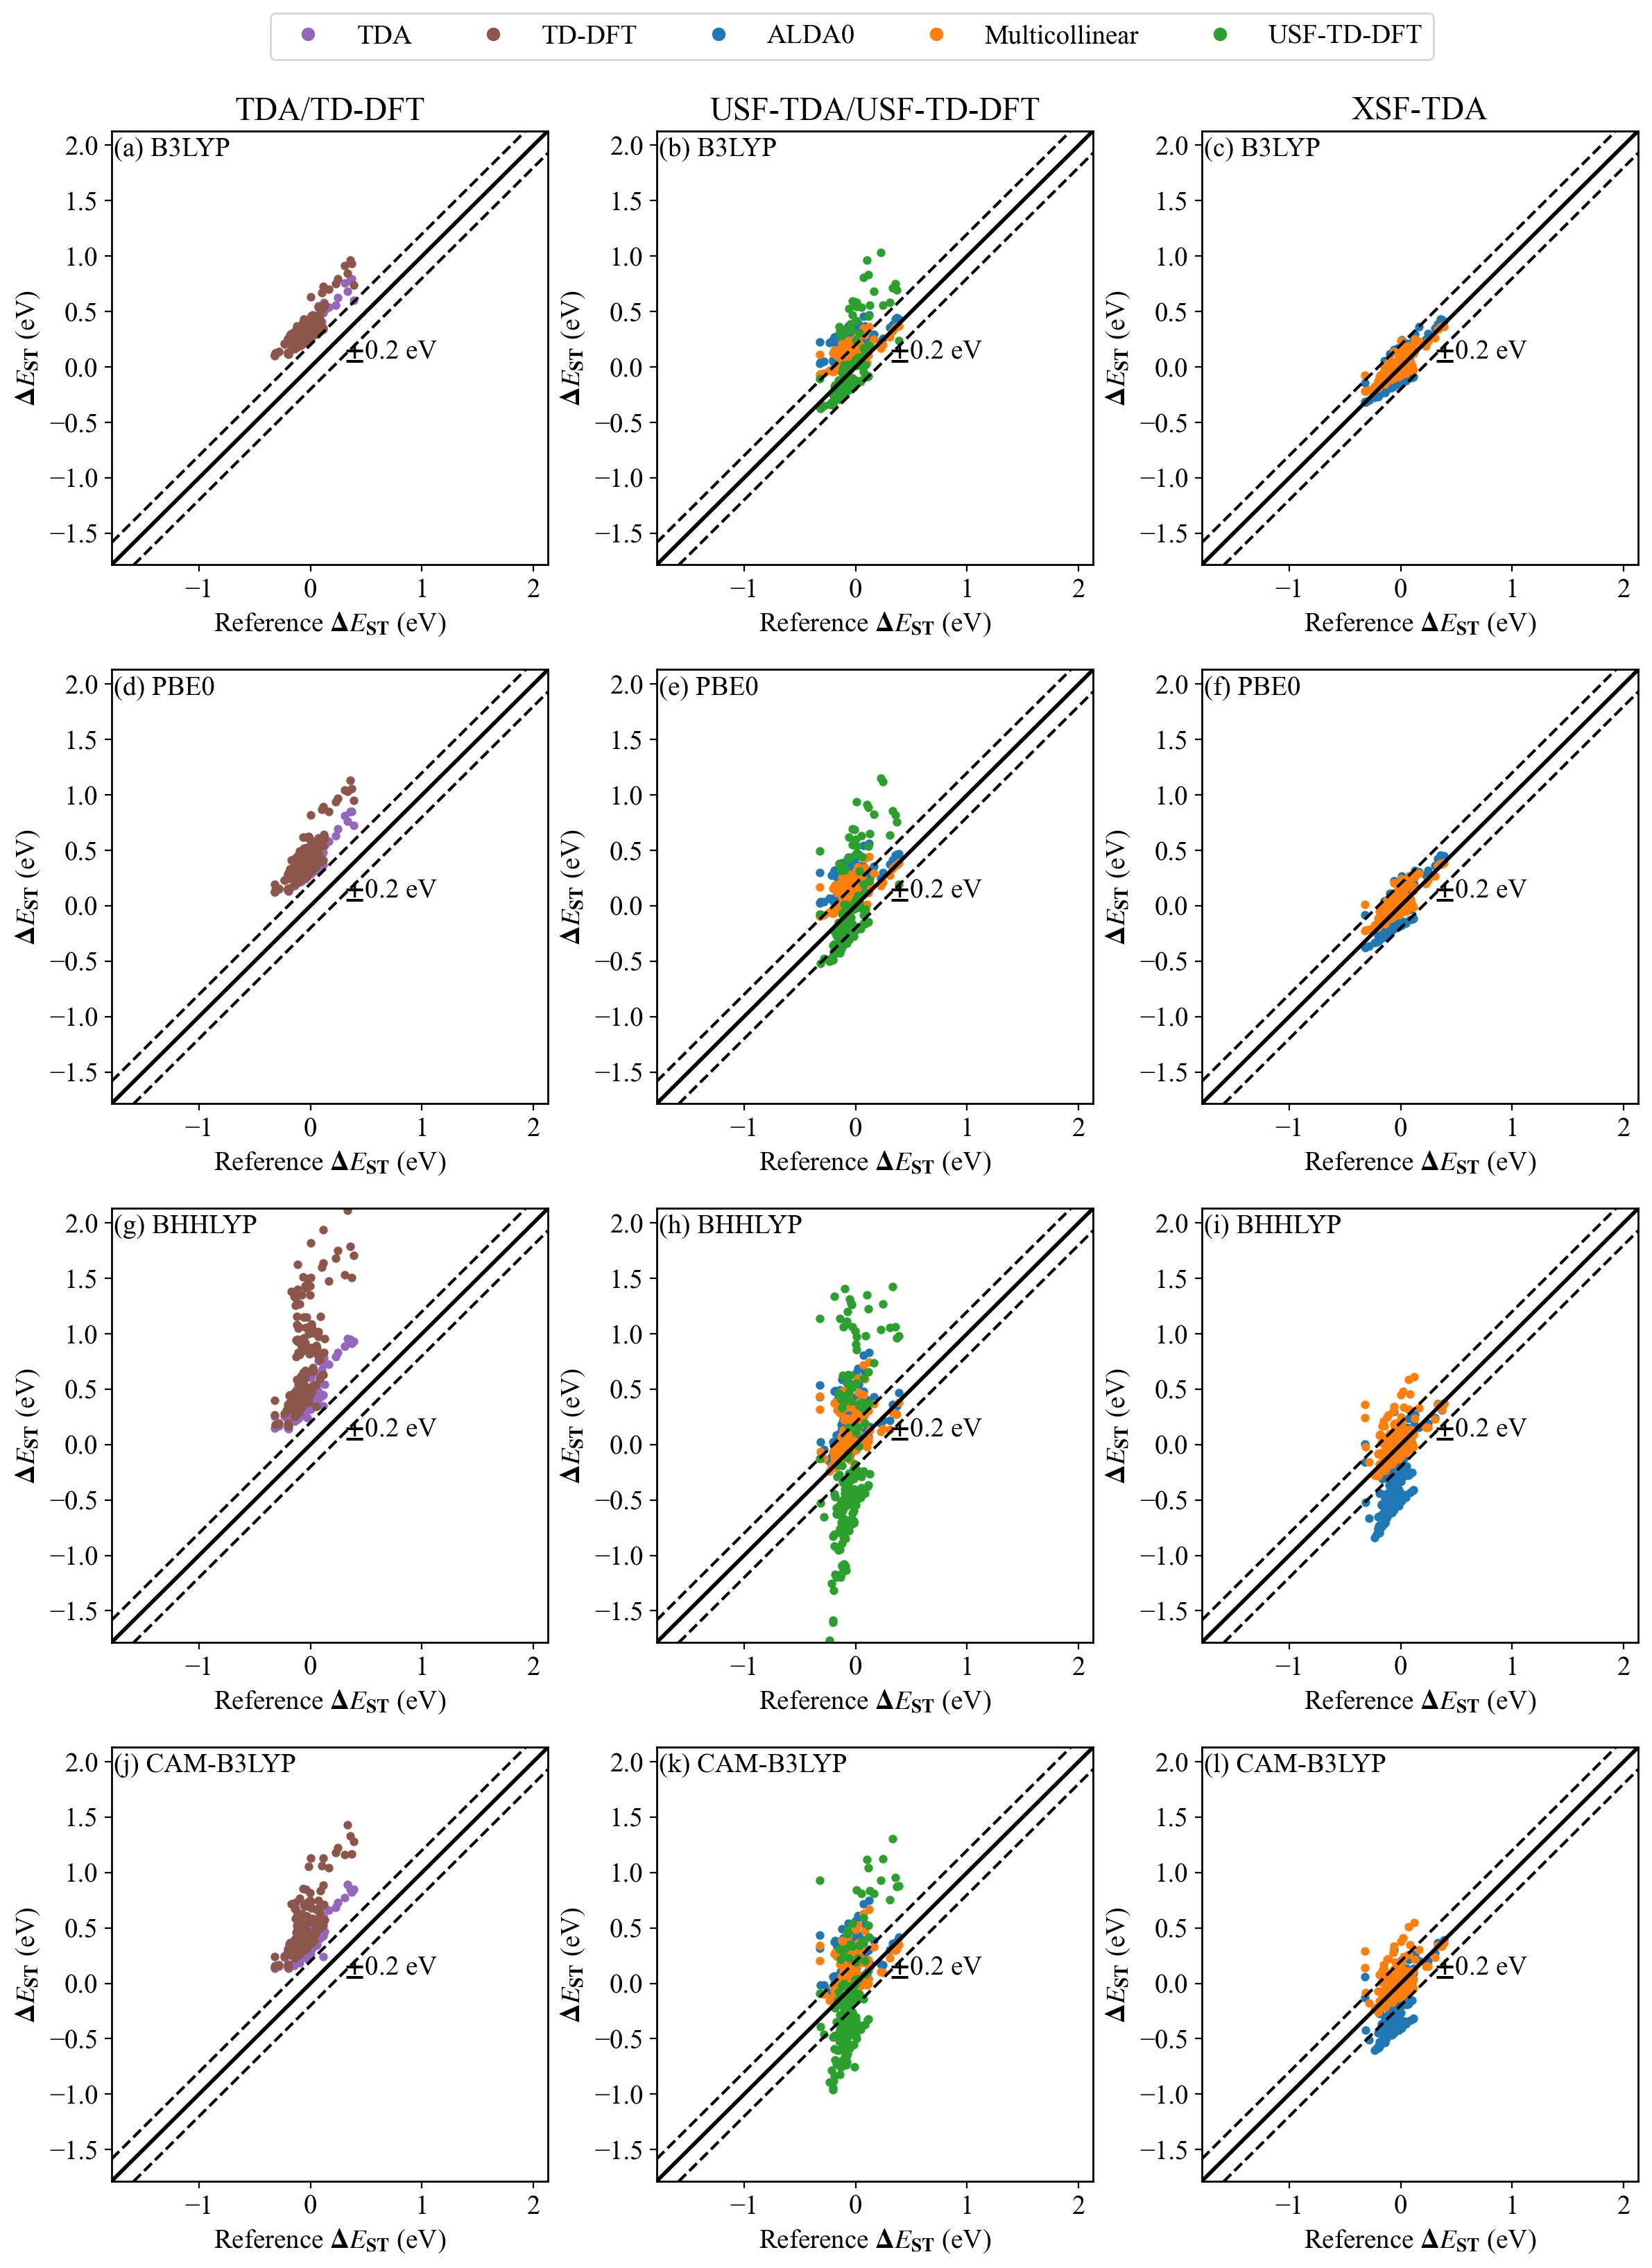

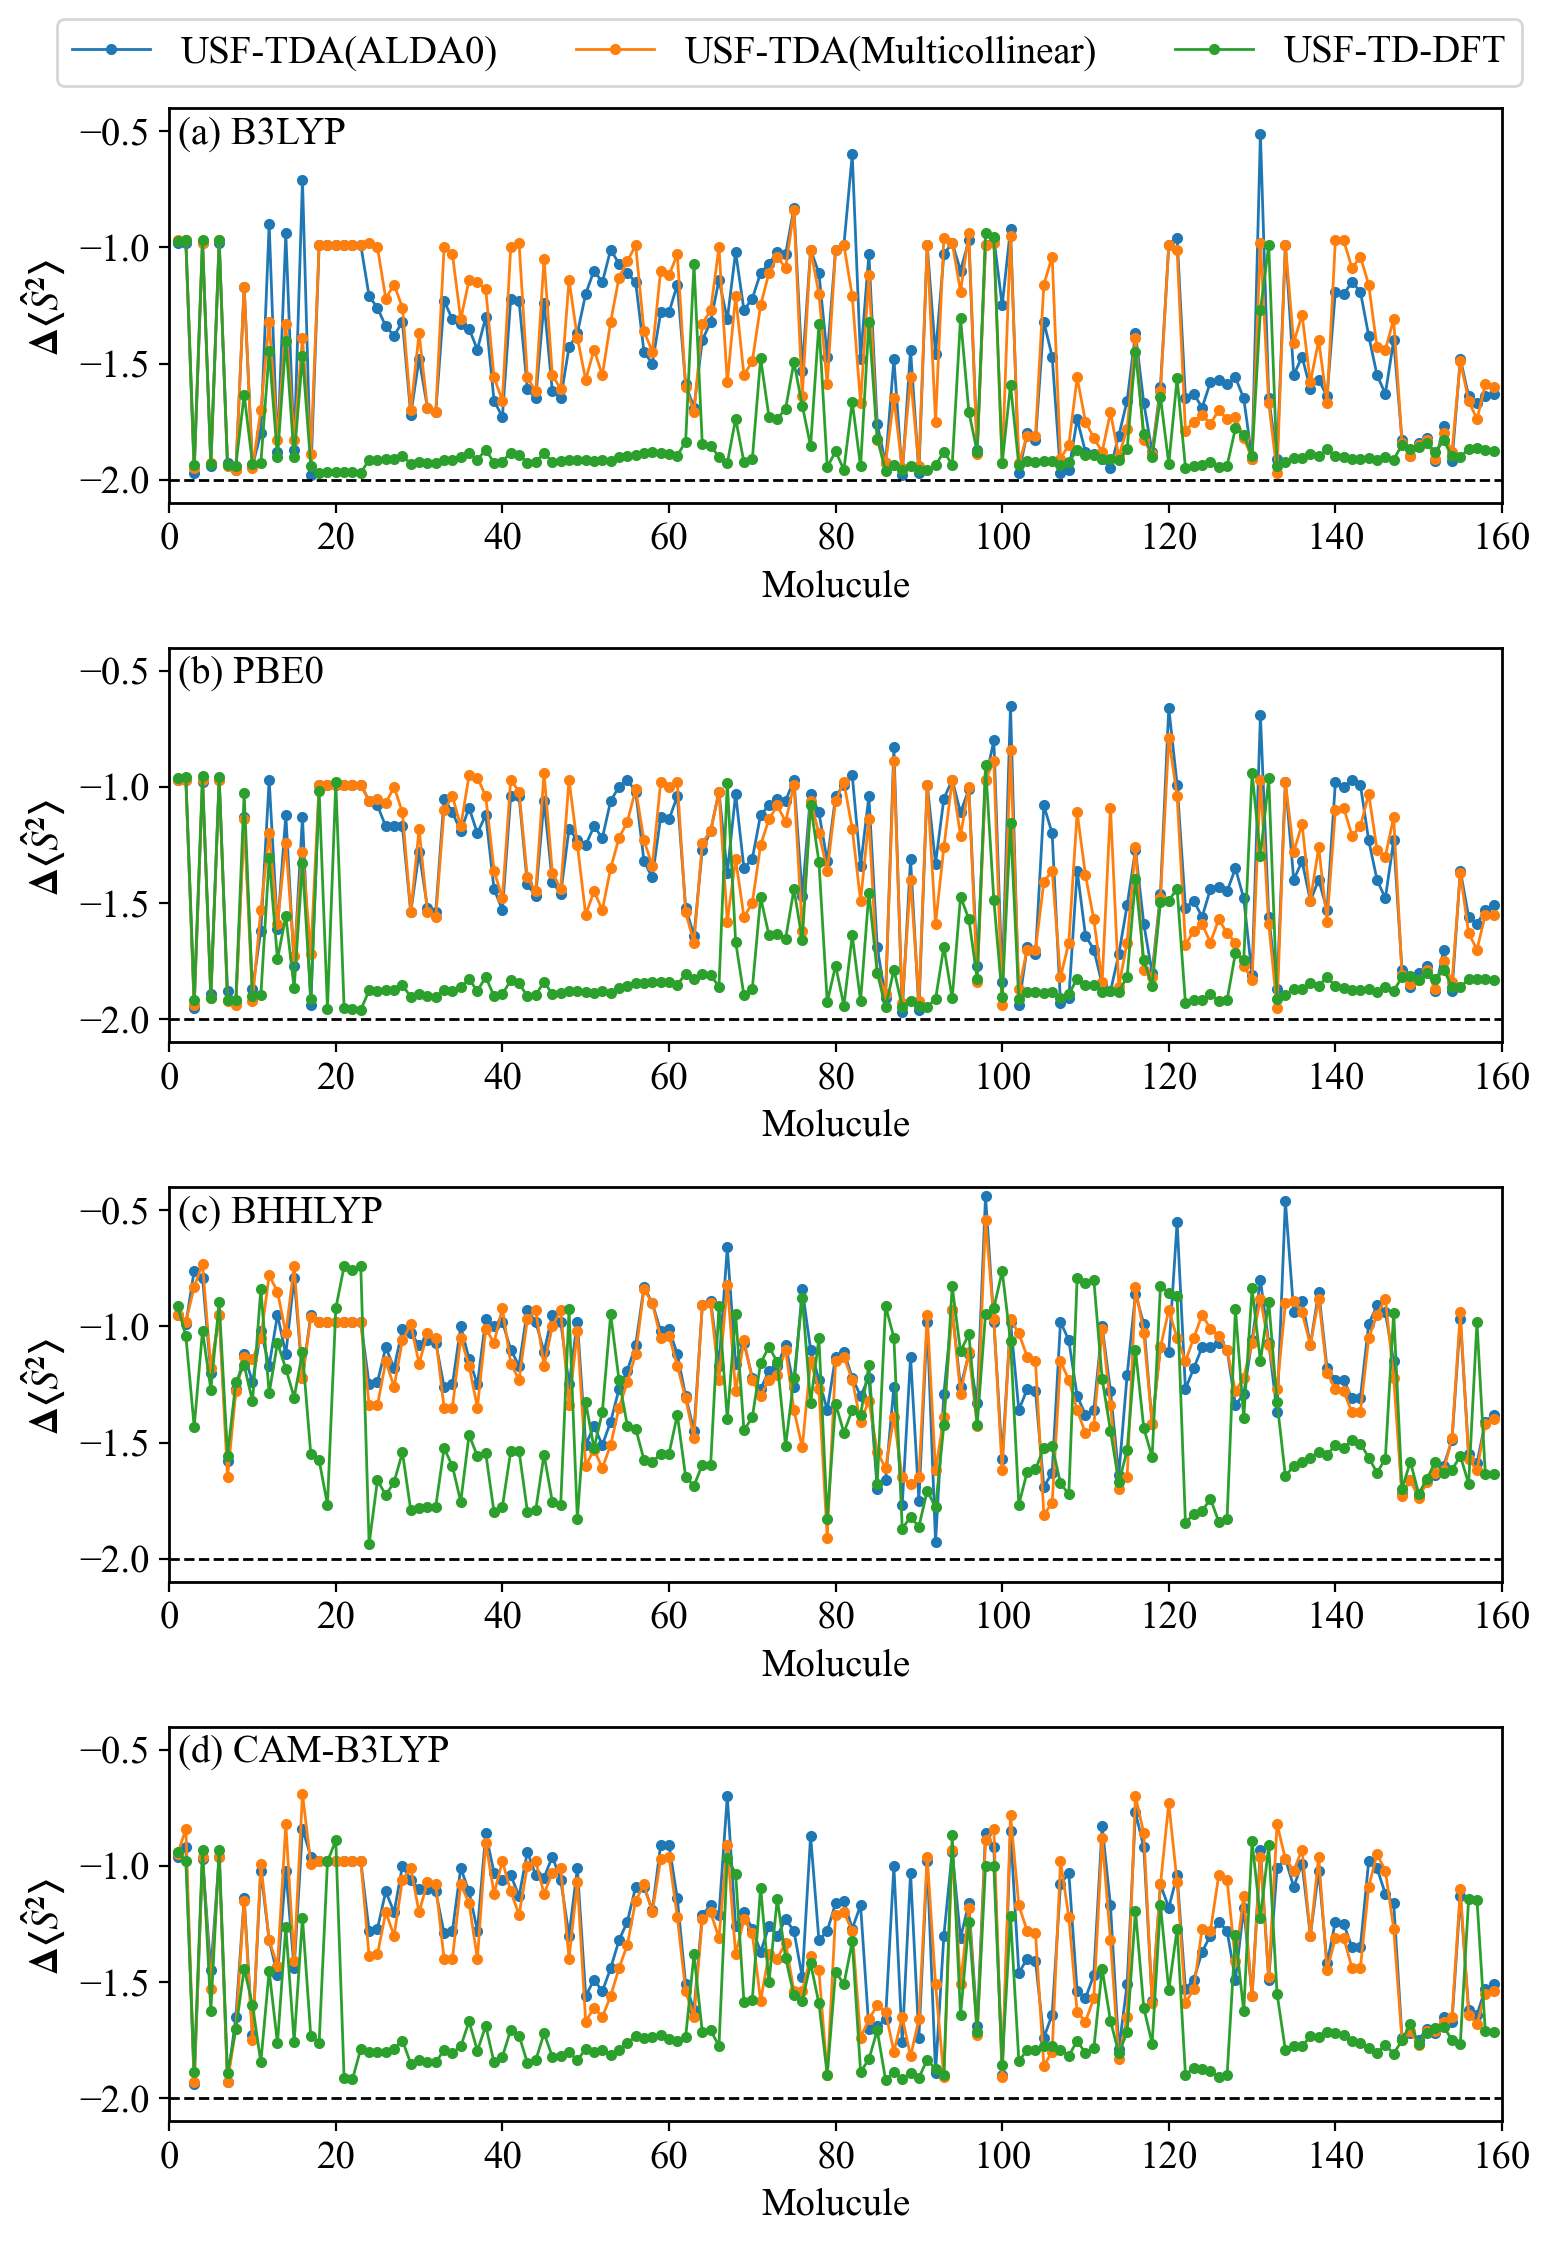

In [3]:
path = 'TADF_all.xlsx'

def nah159_data(path):
    ref,b3lyp_data,pbe0_data,bhhlyp_data, cam_data,ds2_data = read_xlsx(path,'NAH159',159)
    b3lyp_tda,b3lyp_tddft,b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_usftddft,b3lyp_alda0_xsf,b3lyp_mc_xsf = b3lyp_data
    pbe0_tda,pbe0_tddft,pbe0_alda0_usf,pbe0_mc_usf,pbe0_usftddft,pbe0_alda0_xsf,pbe0_mc_xsf = pbe0_data
    bhhlyp_tda,bhhlyp_tddft,bhhlyp_alda0_usf,bhhlyp_mc_usf,bhhlyp_usftddft,bhhlyp_alda0_xsf,bhhlyp_mc_xsf = bhhlyp_data
    cam_tda,cam_tddft,cam_alda0_usf,cam_mc_usf,cam_usftddft,cam_alda0_xsf,cam_mc_xsf = cam_data
    ds2_b3lyp_usftddft,ds2_b3lyp_alda0,ds2_b3lyp_mc,ds2_pbe0_usftddft,ds2_pbe0_alda0,ds2_pbe0_mc,\
    ds2_bhhlyp_usftddft,ds2_bhhlyp_alda0,ds2_bhhlyp_mc,ds2_cam_usftddft,ds2_cam_alda0,ds2_cam_mc = ds2_data

    print('Statistical analysis ')
    print('B3LYP TDA TDDFT USF-TD-DFT USF-TDA(ALDA0) XSF-TDA(ALDA0) USF-TDA(MC) XSF-TDA(MC)')
    calculate_error([ref,b3lyp_tda,b3lyp_tddft,b3lyp_usftddft,b3lyp_alda0_usf,b3lyp_alda0_xsf,b3lyp_mc_usf,b3lyp_mc_xsf],sign=1)
    print('PBE0 TDA TDDFT USF-TD-DFT USF-TDA(ALDA0) XSF-TDA(ALDA0) USF-TDA(MC) XSF-TDA(MC)')
    calculate_error([ref,pbe0_tda,pbe0_tddft,pbe0_usftddft,pbe0_alda0_usf,pbe0_alda0_xsf,pbe0_mc_usf,pbe0_mc_xsf],sign=1)
    print('BHHLYP TDA TDDFT USF-TD-DFT USF-TDA(ALDA0) XSF-TDA(ALDA0) USF-TDA(MC) XSF-TDA(MC)')
    calculate_error([ref,bhhlyp_tda,bhhlyp_tddft,bhhlyp_usftddft,bhhlyp_alda0_usf,bhhlyp_alda0_xsf,bhhlyp_mc_usf,bhhlyp_mc_xsf],sign=1)
    print('CAM_B3LYP TDA TDDFT USF-TD-DFT USF-TDA(ALDA0) XSF-TDA(ALDA0) USF-TDA(MC) XSF-TDA(MC)')
    calculate_error([ref,cam_tda,cam_tddft,cam_usftddft,cam_alda0_usf,cam_alda0_xsf,cam_mc_usf,cam_mc_xsf],sign=1)


    v_max = max(np.max(ref),np.max(b3lyp_data),np.max(pbe0_data),np.max(bhhlyp_data), np.max(cam_data))
    v_min = min(np.min(ref),np.min(b3lyp_data),np.min(pbe0_data),np.min(bhhlyp_data), np.min(cam_data))
    draw_scatter(ref,b3lyp_data,pbe0_data,bhhlyp_data,cam_data,v_max,v_min,'nah159_data')

    # \Delta S^{2}
    fig,axs = plt.subplots(4,1,figsize=(8,11))
    x = np.arange(len(ref))+1
    x_data = [[ds2_b3lyp_alda0,ds2_b3lyp_mc,ds2_b3lyp_usftddft],
              [ds2_pbe0_alda0,ds2_pbe0_mc,ds2_pbe0_usftddft],
              [ds2_bhhlyp_alda0,ds2_bhhlyp_mc,ds2_bhhlyp_usftddft],
              [ds2_cam_alda0,ds2_cam_mc,ds2_cam_usftddft]]
    x_data_label = ['(a) B3LYP','(b) PBE0','(c) BHHLYP','(d) CAM-B3LYP']
    for i in range(4):
        axs[i].plot(x,x_data[i][0],marker='.',label='USF-TDA(ALDA0)',color='#1f77b4')
        axs[i].plot(x,x_data[i][1],marker='.',label='USF-TDA(Multicollinear)',color='#ff7f0e')
        axs[i].plot(x,x_data[i][2],label='USF-TD-DFT',marker='.',color='#2ca02c')
        axs[i].set_xlabel('Molucule')
        axs[i].set_ylabel(r'$\Delta\langle \hat{S}^{2}\rangle$ ')
        axs[i].set_xlim((0,160))
        axs[i].set_ylim((-2.1,-0.4))
        axs[i].text(1,-0.55,f'{x_data_label[i]}')
        axs[i].axhline(y=-2,linestyle='--',color='black')

    legend_elements = [
            Line2D([0], [0], label=r'USF-TDA(ALDA0)',color='#1f77b4',marker='.'),
            Line2D([0], [0], label=r'USF-TDA(Multicollinear)',color='#ff7f0e',marker='.'),
            Line2D([0],[0],label='USF-TD-DFT',color='#2ca02c',marker='.')]
    fig.legend(
                handles=legend_elements,
                loc='upper center',
                bbox_to_anchor=(0.51, 1.03),  # 调整图例位置（y=1.05 表示在顶部上方）
                ncol=3,                      # 图例分 4 列显示
                #frameon=False,               # 去掉图例边框
                fontsize=14
            )
        
    plt.tight_layout()
    plt.savefig('nah159_ds2.pdf',bbox_inches='tight')
    plt.show()


nah159_data('TADF_all.xlsx')

Statistical analysis 
B3LYP
MSE   0.310054
MAE   0.310054
RMSE  0.3237332245582111
SE    0.015968459506953386
MAX   0.45149
/////////////////////
MSE   0.27724828571428567
MAE   0.27724828571428567
RMSE  0.2870294511668495
SE    0.012740964394231623
MAX   0.41183
/////////////////////
MSE   -0.0017734085575771442
MAE   0.045953907554297145
RMSE  0.06576612311903172
SE    0.011274695733726229
MAX   0.23411104660560003
/////////////////////
MSE   0.13434257142857148
MAE   0.14635285714285717
RMSE  0.16049340190265055
SE    0.015058909377981584
MAX   0.23968
/////////////////////
MSE   -0.08122962857142858
MAE   0.08122962857142858
RMSE  0.0865595671280766
SE    0.005128656811737457
MAX   -0.16080999999999998
/////////////////////
MSE   0.08336914285714286
MAE   0.10178342857142857
RMSE  0.11081541940155647
SE    0.012520152221880675
MAX   0.17811
/////////////////////
MSE   -0.03496430285714286
MAE   0.038931731428571426
RMSE  0.051778849073000566
SE    0.006549689568392587
MAX   -0.1589

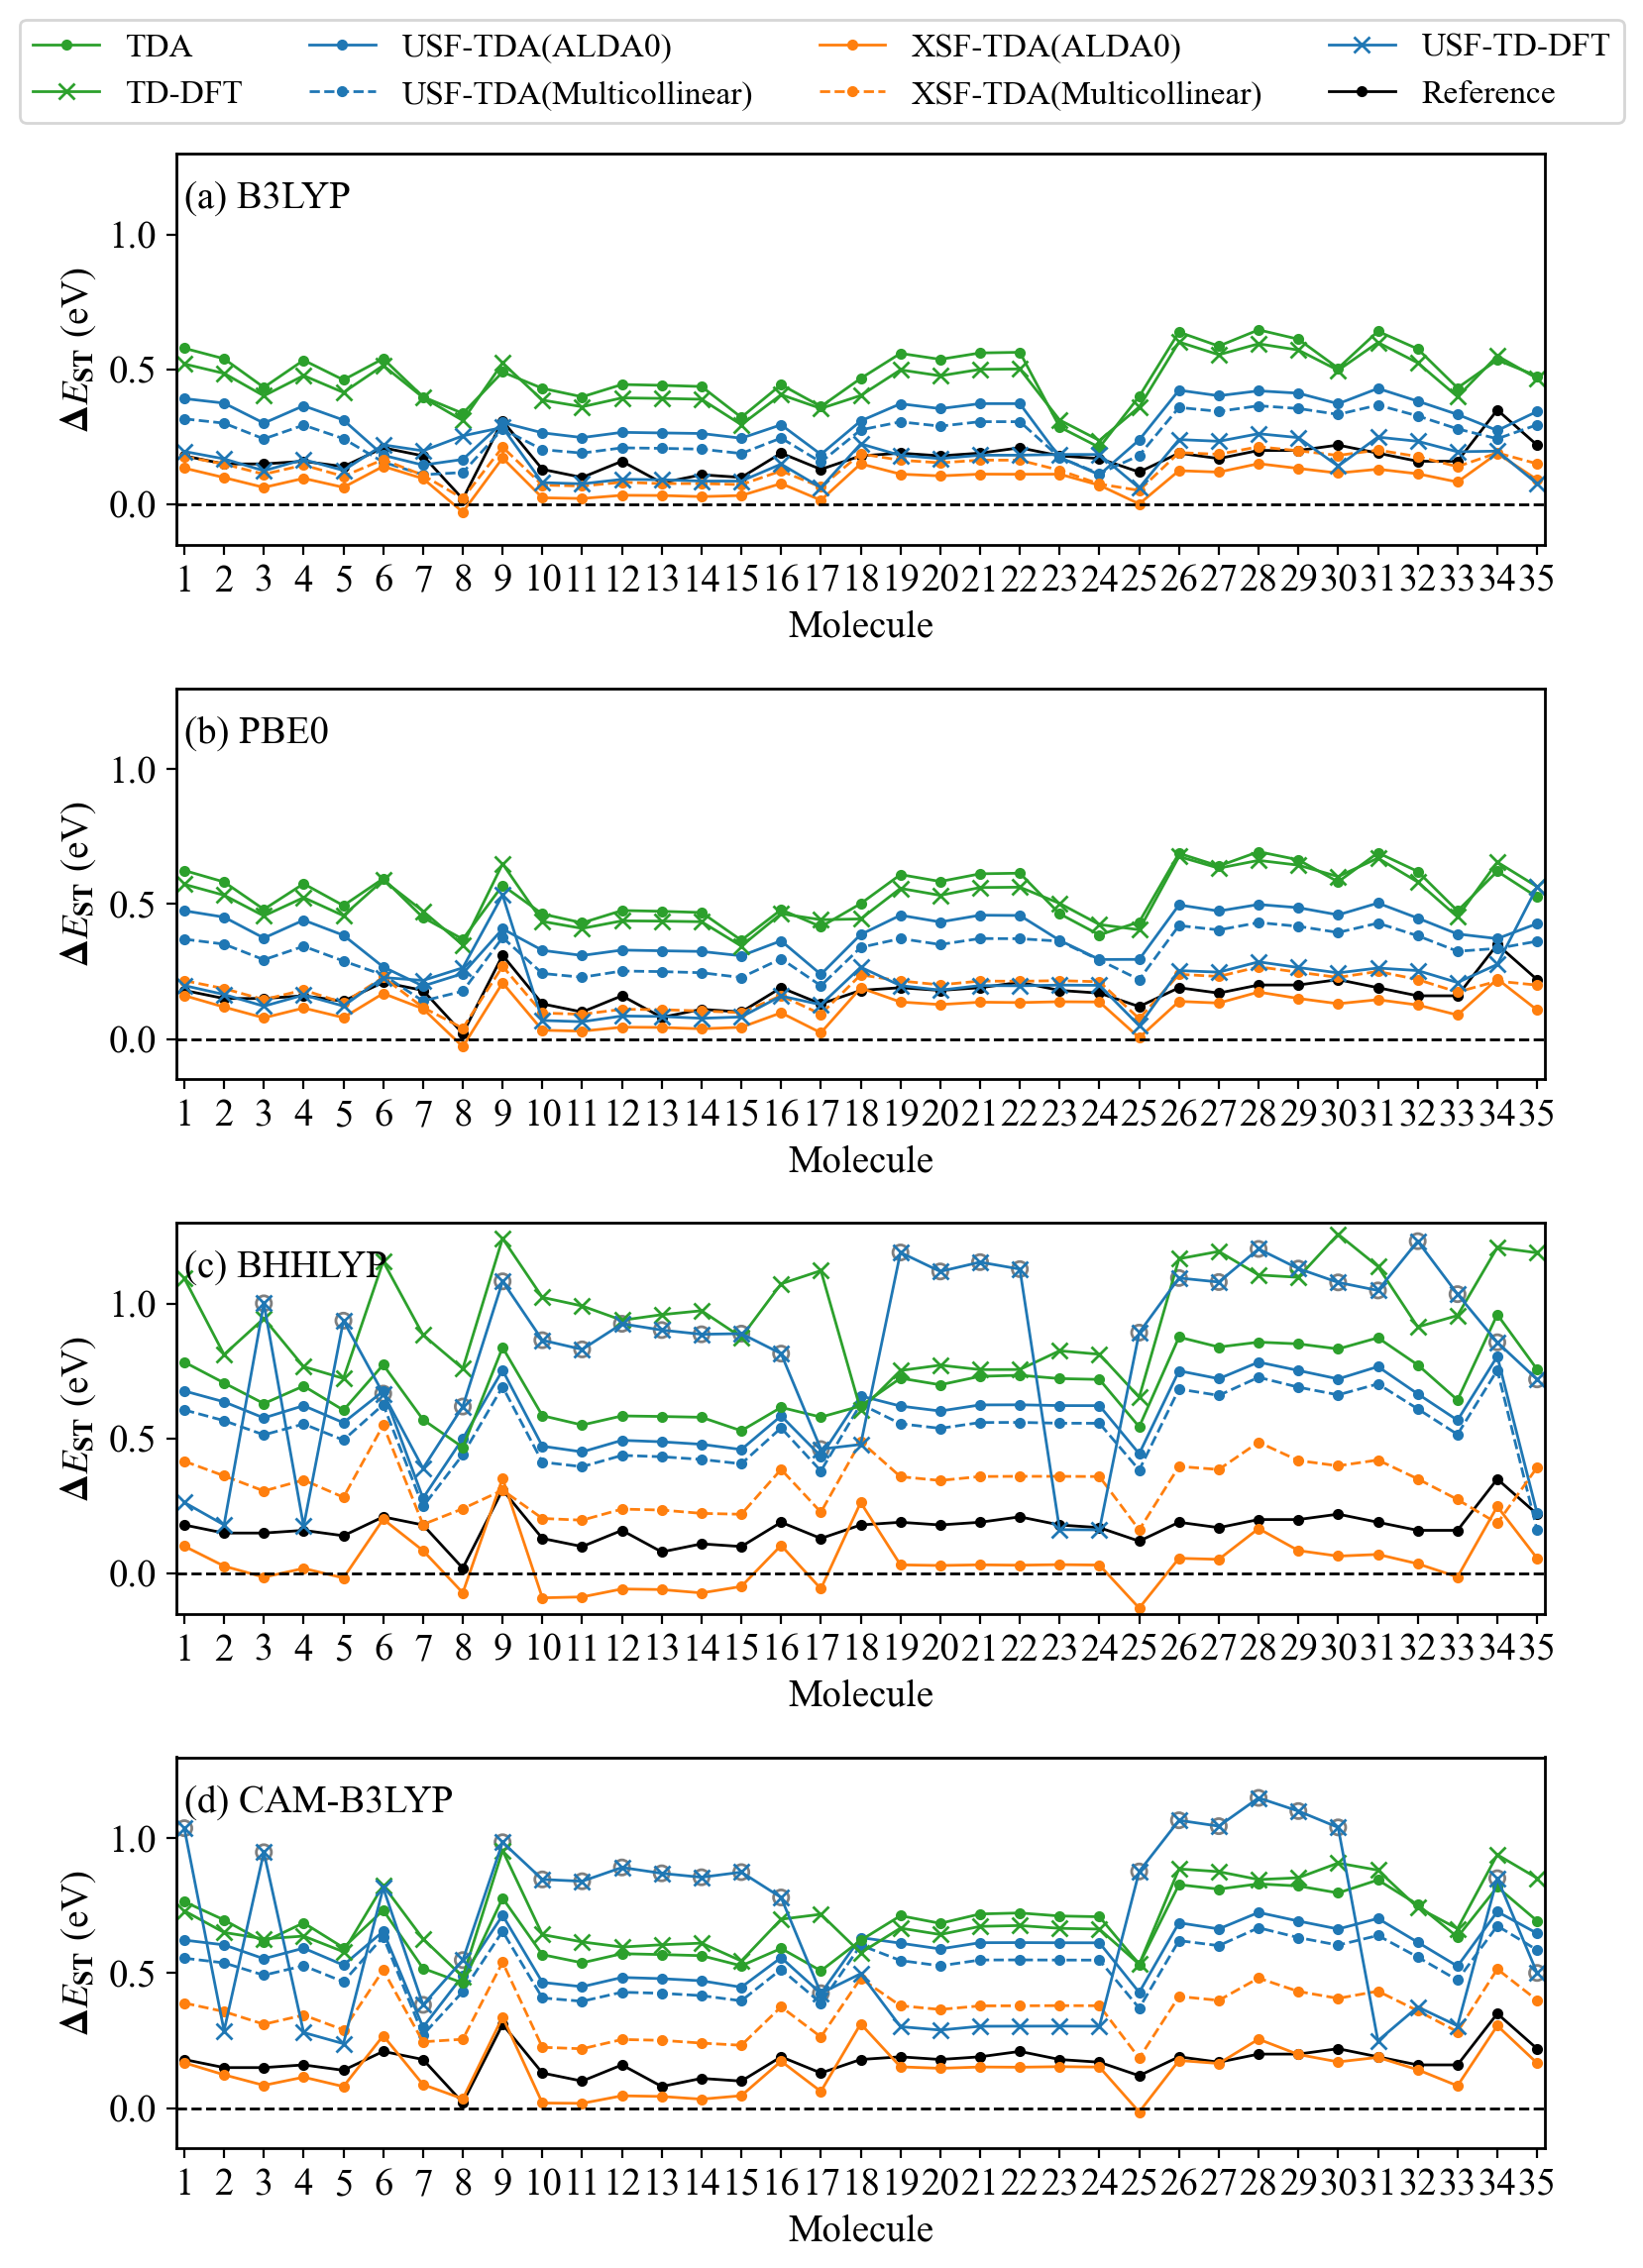

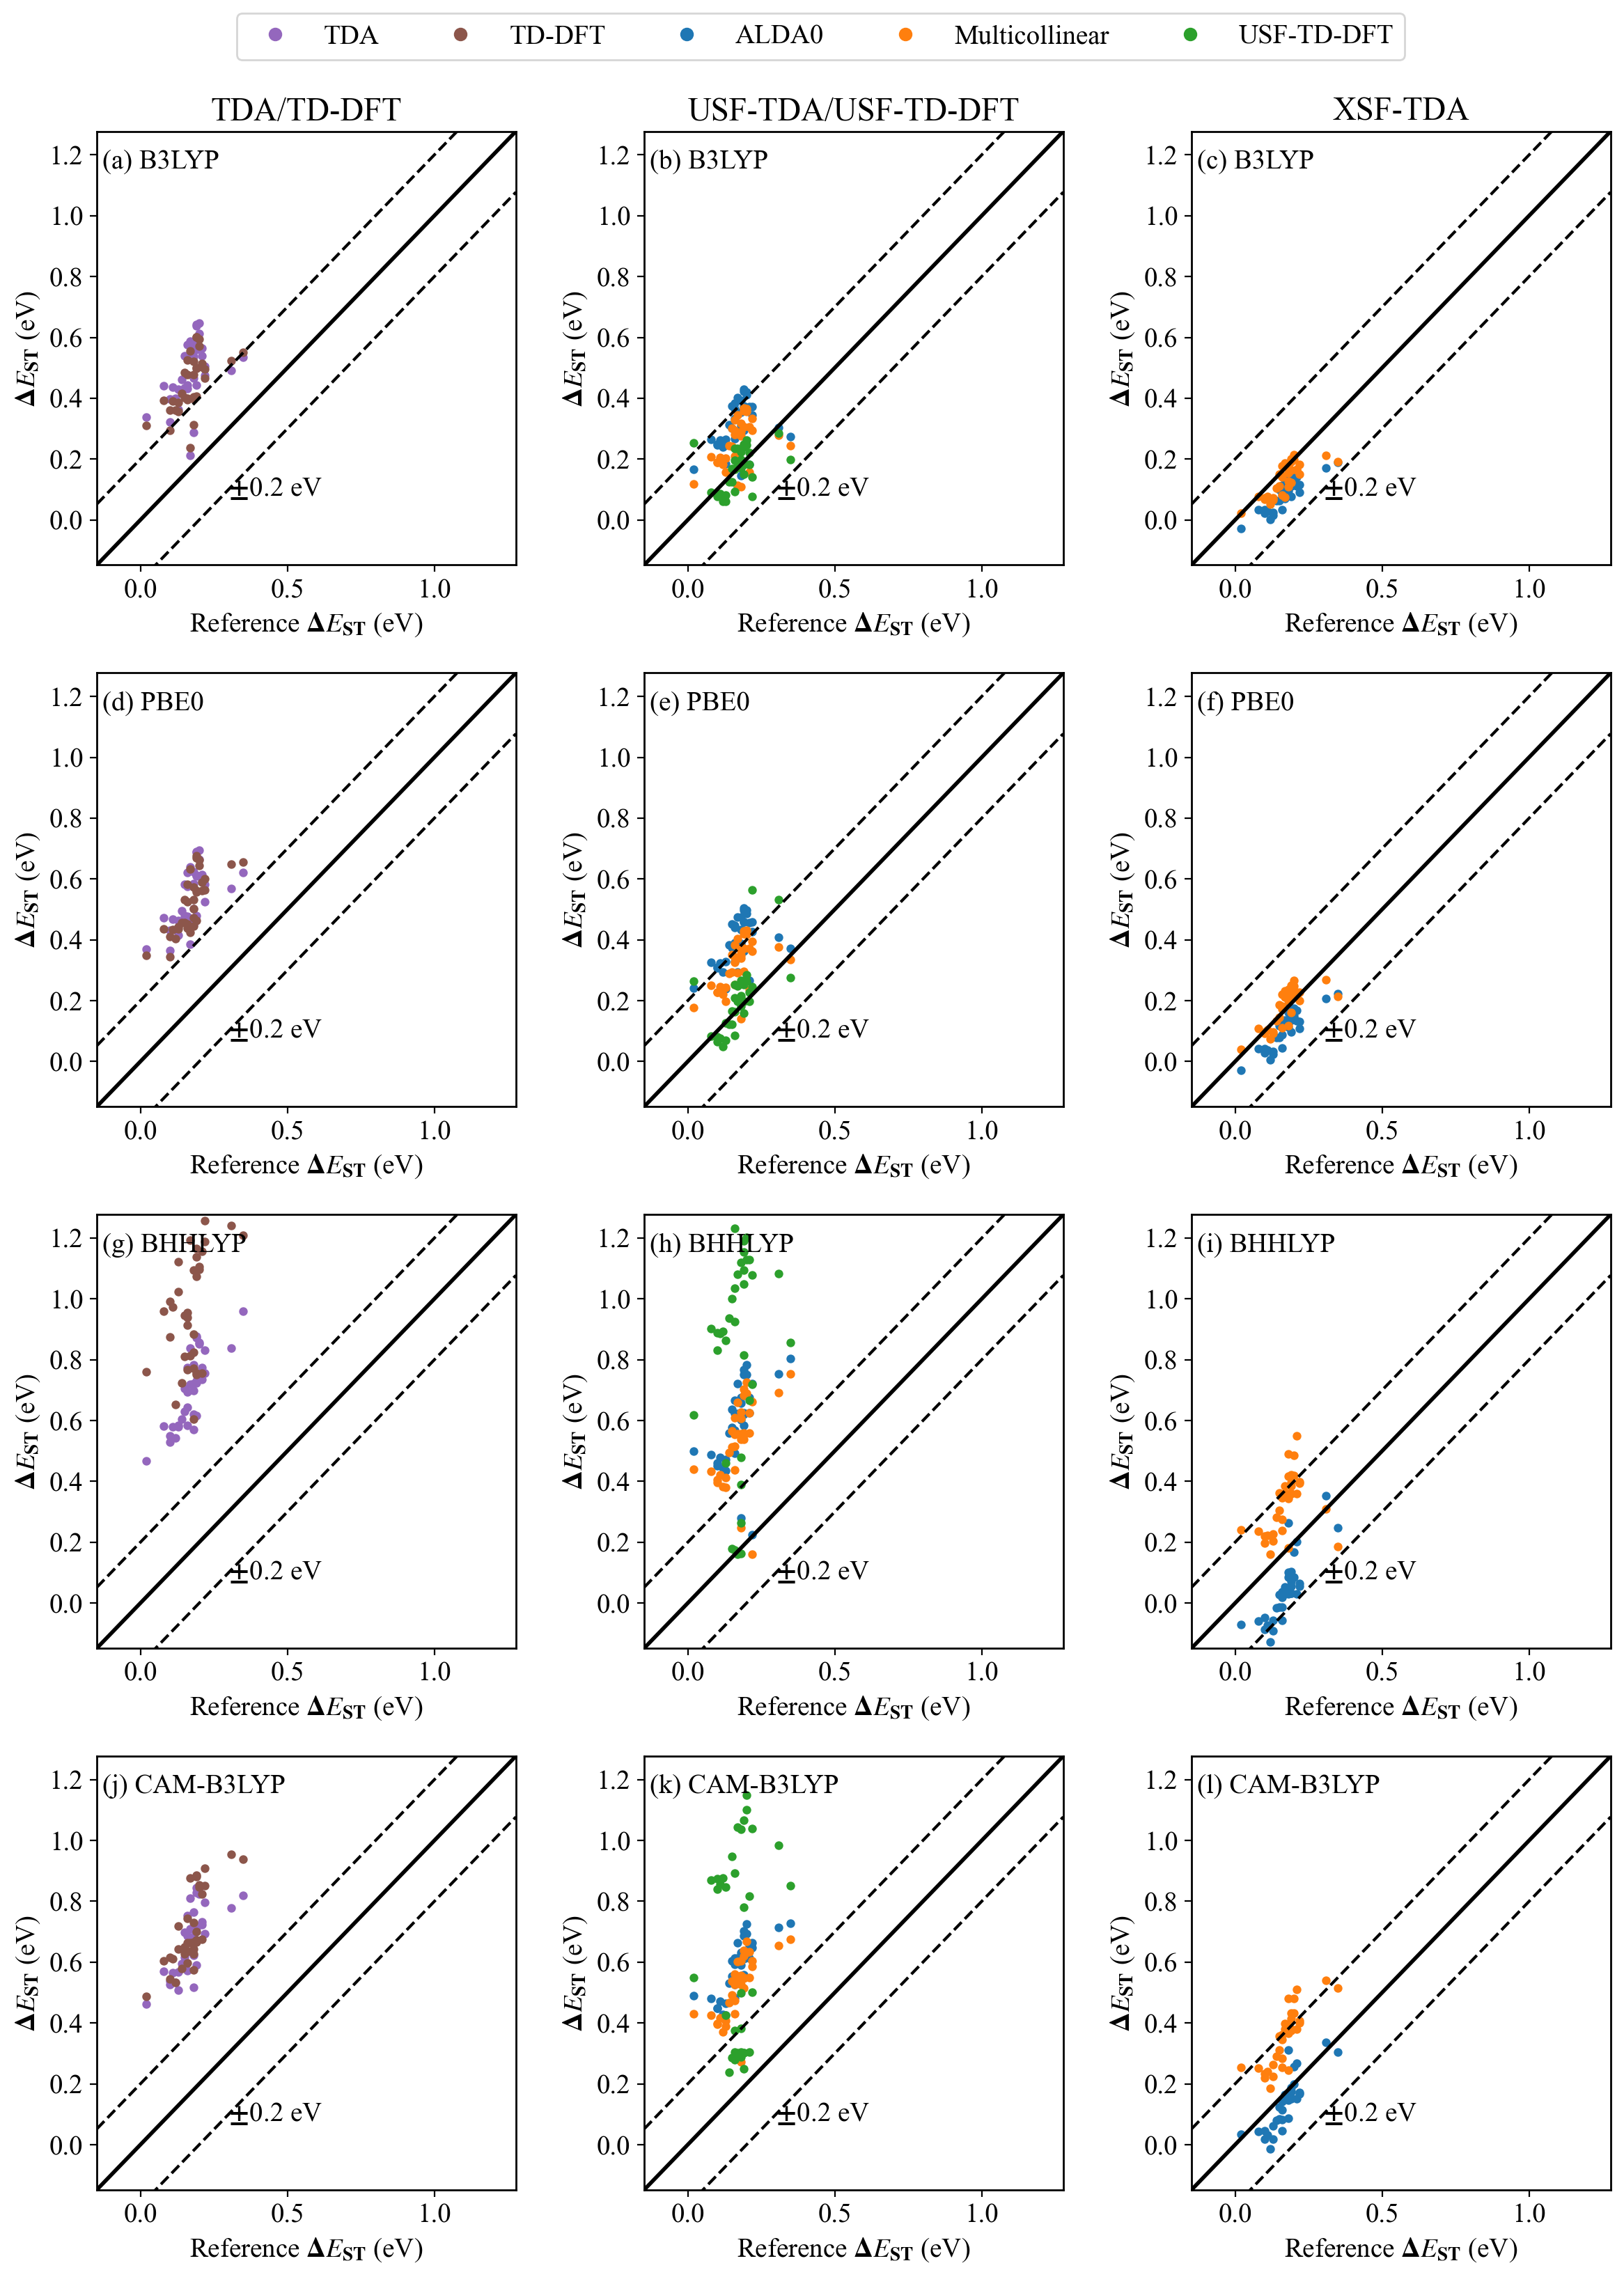

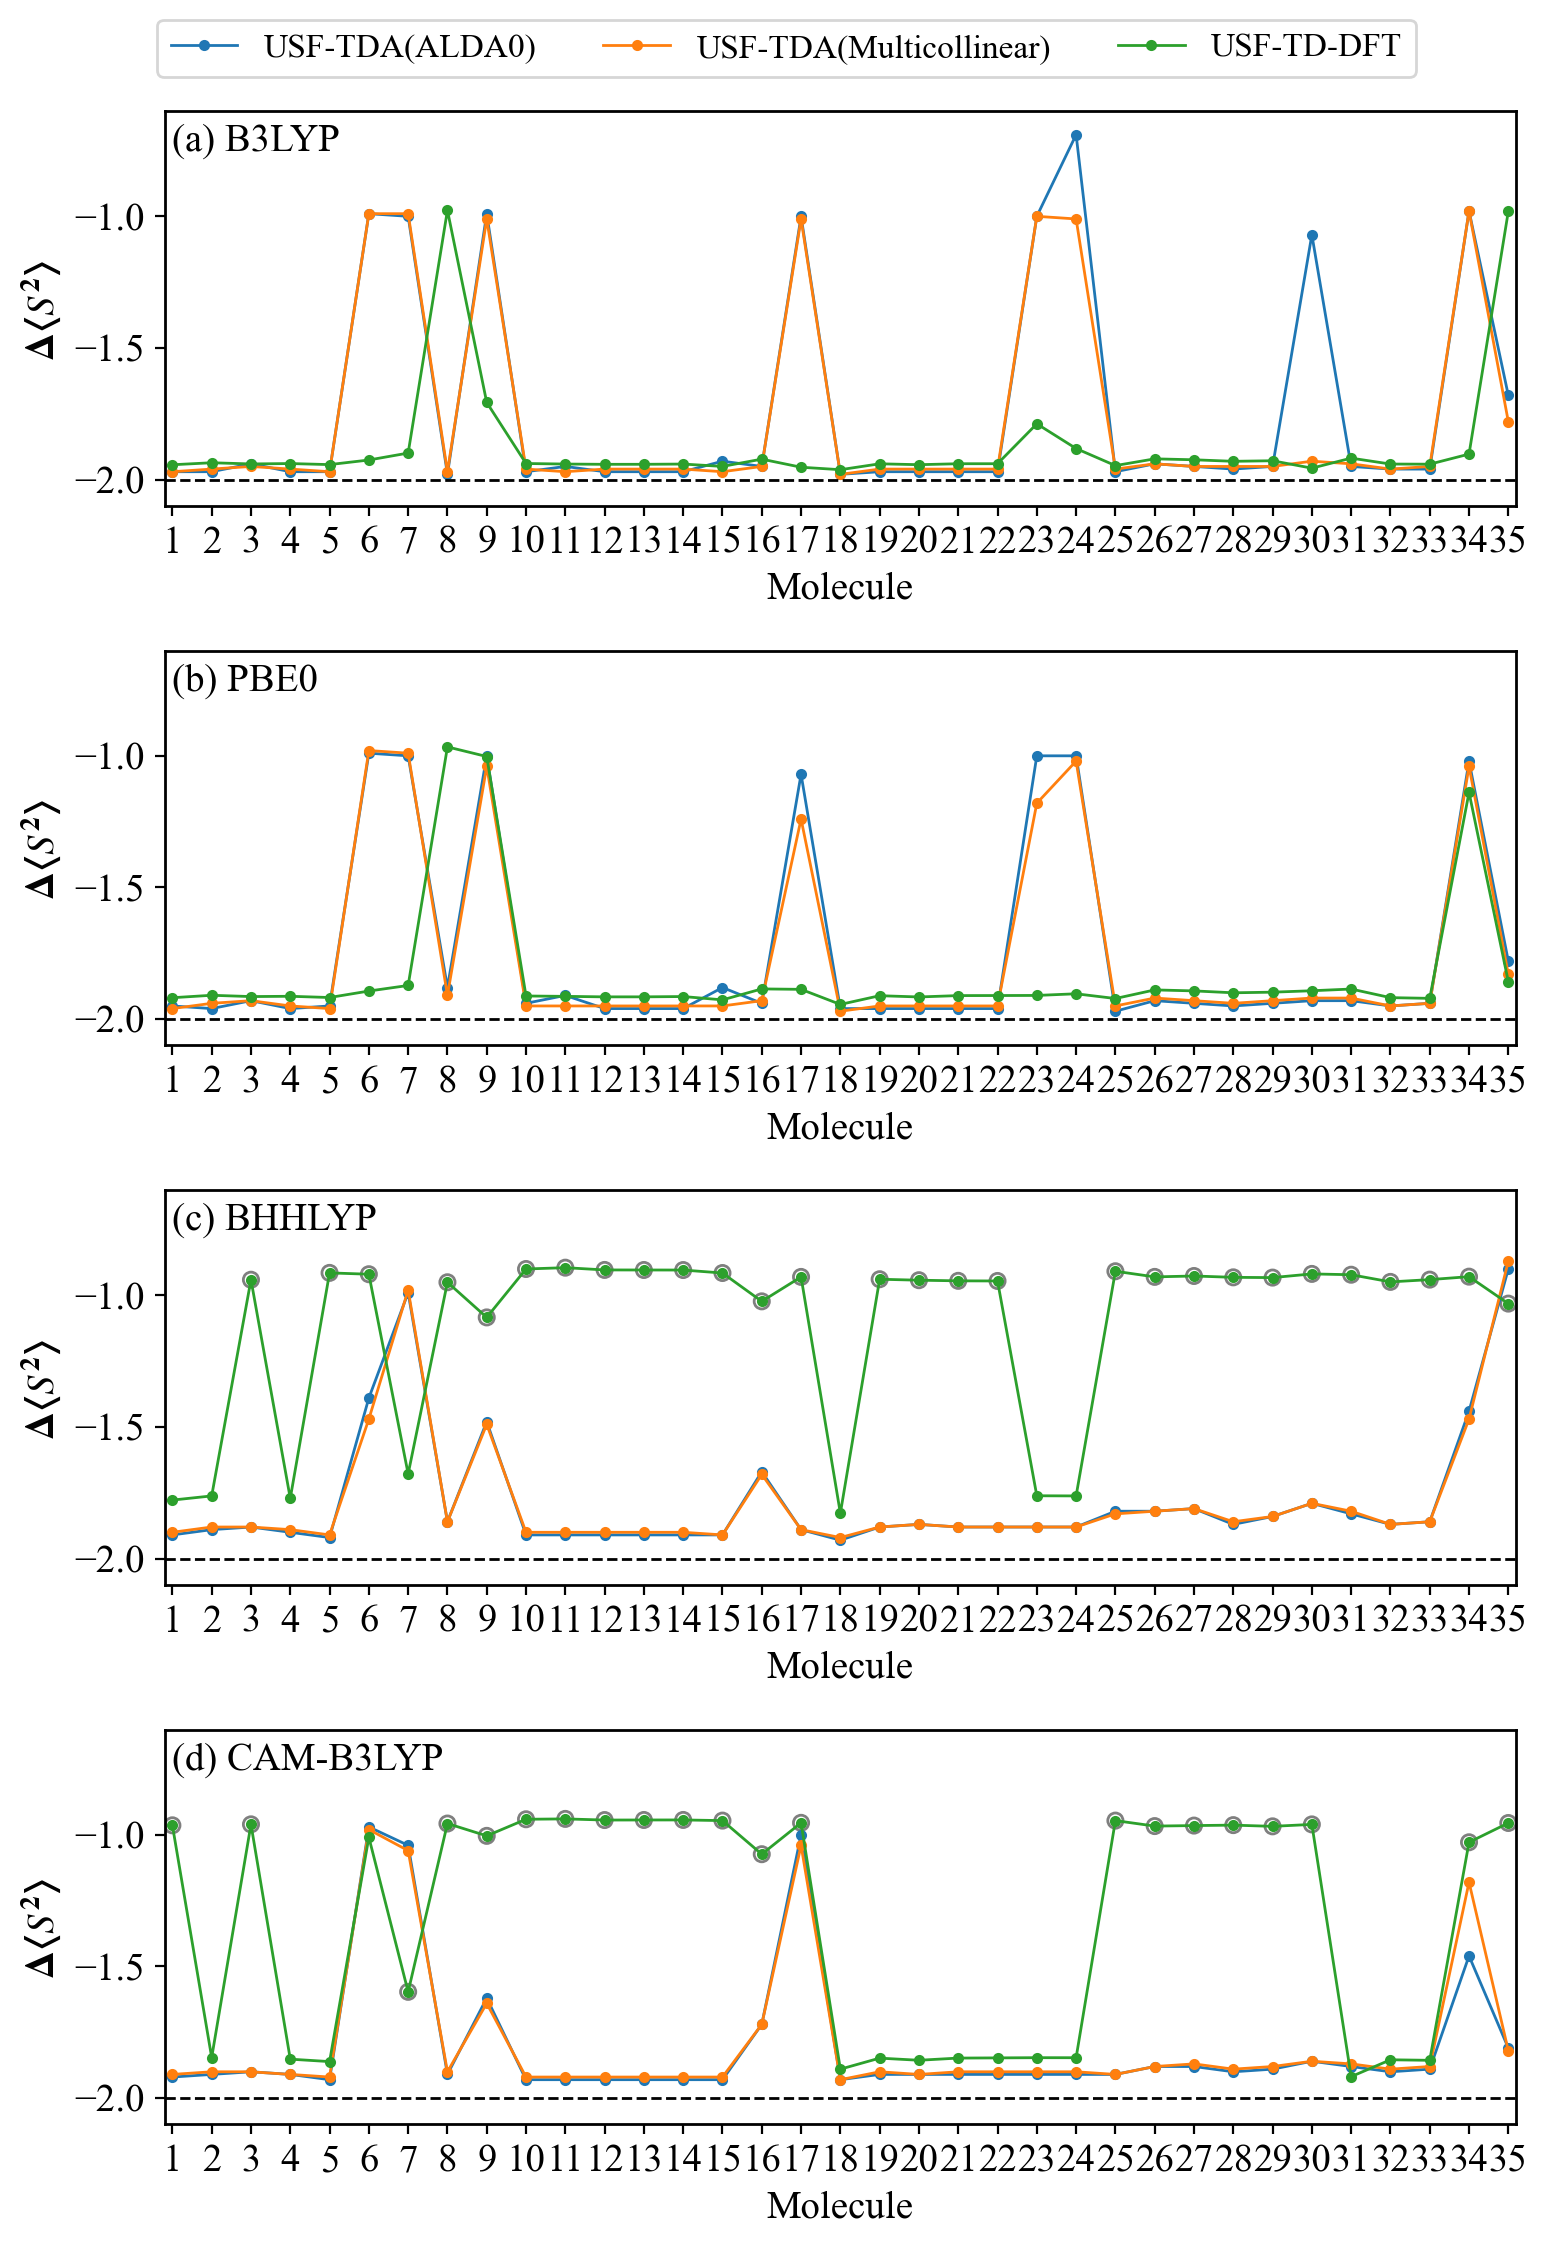

In [10]:
path = 'TADF_all.xlsx'

def MR_TADF(path):

    ref,b3lyp_data,pbe0_data,bhhlyp_data, cam_data,ds2_data = read_xlsx(path,'MR-TADF',35)
    b3lyp_tda,b3lyp_tddft,b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_usftddft,b3lyp_alda0_xsf,b3lyp_mc_xsf = b3lyp_data
    pbe0_tda,pbe0_tddft,pbe0_alda0_usf,pbe0_mc_usf,pbe0_usftddft,pbe0_alda0_xsf,pbe0_mc_xsf = pbe0_data
    bhhlyp_tda,bhhlyp_tddft,bhhlyp_alda0_usf,bhhlyp_mc_usf,bhhlyp_usftddft,bhhlyp_alda0_xsf,bhhlyp_mc_xsf = bhhlyp_data
    cam_tda,cam_tddft,cam_alda0_usf,cam_mc_usf,cam_usftddft,cam_alda0_xsf,cam_mc_xsf = cam_data
    ds2_b3lyp_usftddft,ds2_b3lyp_alda0,ds2_b3lyp_mc,ds2_pbe0_usftddft,ds2_pbe0_alda0,ds2_pbe0_mc,\
    ds2_bhhlyp_usftddft,ds2_bhhlyp_alda0,ds2_bhhlyp_mc,ds2_cam_usftddft,ds2_cam_alda0,ds2_cam_mc = ds2_data
    
    print('Statistical analysis ')
    print('B3LYP')
    calculate_error([ref,b3lyp_tda,b3lyp_tddft,b3lyp_usftddft,b3lyp_alda0_usf,b3lyp_alda0_xsf,b3lyp_mc_usf,b3lyp_mc_xsf])
    print('PBE0')
    calculate_error([ref,pbe0_tda,pbe0_tddft,pbe0_usftddft,pbe0_alda0_usf,pbe0_alda0_xsf,pbe0_mc_usf,pbe0_mc_xsf])
    print('BHHLYP')
    calculate_error([ref,bhhlyp_tda,bhhlyp_tddft,bhhlyp_usftddft,bhhlyp_alda0_usf,bhhlyp_alda0_xsf,bhhlyp_mc_usf,bhhlyp_mc_xsf])
    print('CAM_B3LYP')
    calculate_error([ref,cam_tda,cam_tddft,cam_usftddft,cam_alda0_usf,cam_alda0_xsf,cam_mc_usf,cam_mc_xsf])

    x = np.arange(len(ref))+1
    fig,axs = plt.subplots(4,1,figsize=(8,11))
    x_data = [[b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_alda0_xsf,b3lyp_mc_xsf,b3lyp_tda,b3lyp_tddft,b3lyp_usftddft],
              [pbe0_alda0_usf,pbe0_mc_usf,pbe0_alda0_xsf,pbe0_mc_xsf,pbe0_tda,pbe0_tddft,pbe0_usftddft],
              [bhhlyp_alda0_usf,bhhlyp_mc_usf,bhhlyp_alda0_xsf,bhhlyp_mc_xsf,bhhlyp_tda,bhhlyp_tddft,bhhlyp_usftddft],
              [cam_alda0_usf,cam_mc_usf,cam_alda0_xsf,cam_mc_xsf,cam_tda,cam_tddft,cam_usftddft]]
    x_data_label = ['(a) B3LYP','(b) PBE0','(c) BHHLYP', '(d) CAM-B3LYP']
    usftddft_im_cam = [1,3,7,8,9,10,11,12,13,14,15,16,17,25,26,27,28,29,30,34,35]
    usftddft_im_v_cam = [cam_usftddft[i-1] for i in usftddft_im_cam]
    usftddft_im_bhhlyp = [3,5,6,8,9,10,11,12,13,14,15,16,17,19,20,21,22,25,26,27,28,29,30,31,32,33,34,35]
    usftddft_im_v_bhhlyp = [bhhlyp_usftddft[i-1] for i in usftddft_im_bhhlyp]
    for i in range(4):
        axs[i].plot(x,ref,label='Ref.',marker='.',color='black')
        axs[i].plot(x,x_data[i][0],label='USF-TDA(ALDA0)',marker='.',color='#1f77b4')
        axs[i].plot(x,x_data[i][1],label='USF-TDA(Multicollinear)',marker='.',linestyle='--',color='#1f77b4')
        axs[i].plot(x,x_data[i][2],label='XSF-TDA(ALDA0)',marker='.',color='#ff7f0e')
        axs[i].plot(x,x_data[i][3],label='XSF-TDA(Multicollinear)',marker='.',linestyle='--',color='#ff7f0e')
        axs[i].plot(x,x_data[i][4],label='TDA',marker='.',color='#2ca02c')
        axs[i].plot(x,x_data[i][5],label='TD-DFT',marker='x',color='#2ca02c')
        axs[i].plot(x,x_data[i][6],label='USF-TD-DFT',marker='x',color='#1f77b4')
        if i == 2:
            axs[i].scatter(usftddft_im_bhhlyp,usftddft_im_v_bhhlyp,marker='o',s=30,facecolors='none',edgecolors='#7f7f7f')
        if i == 3:
            axs[i].scatter(usftddft_im_cam,usftddft_im_v_cam,marker='o',s=30,facecolors='none',edgecolors='#7f7f7f')
        axs[i].set_xticks(x,x)
        axs[i].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
        axs[i].set_xlabel('Molecule')
        axs[i].set_xlim((0.8,x[-1]+0.2))
        axs[i].set_ylim((-0.15,1.30))
        axs[i].text(1,1.1,f'{x_data_label[i]}')
        axs[i].axhline(y=0, color='black', linestyle='--', linewidth=1)
    legend_elements = [
            Line2D([0],[0],label='TDA',color='#2ca02c',marker='.'),
            Line2D([0],[0],label='TD-DFT',color='#2ca02c',marker='x'),
            Line2D([0], [0], label=r'USF-TDA(ALDA0)',color='#1f77b4',marker='.'),
            Line2D([0], [0], label=r'USF-TDA(Multicollinear)',color='#1f77b4',marker='.',linestyle='--'),
            Line2D([0], [0],  label='XSF-TDA(ALDA0)',color='#ff7f0e',marker='.'),
            Line2D([0],[0],label='XSF-TDA(Multicollinear)',color='#ff7f0e',marker='.',linestyle='--'),
            Line2D([0],[0],label='USF-TD-DFT',color='#1f77b4',marker='x'),
            Line2D([0], [0],  label='Reference',color='black',marker='.'), ]
    fig.legend(
                handles=legend_elements,
                loc='upper center',
                bbox_to_anchor=(0.51, 1.05),  # 调整图例位置（y=1.05 表示在顶部上方）
                ncol=4,                      # 图例分 4 列显示
                #frameon=False,               # 去掉图例边框
                fontsize=12
            )
    plt.tight_layout()
    plt.savefig('mewes_data.pdf',bbox_inches='tight')
    plt.show()

    v_max = max(np.max(ref),np.max(b3lyp_data),np.max(pbe0_data),np.max(bhhlyp_data), np.max(cam_data))
    v_min = min(np.min(ref),np.min(b3lyp_data),np.min(pbe0_data),np.min(bhhlyp_data), np.min(cam_data))
    #b3lyp_data = [b3lyp_tda,b3lyp_tddft,b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_usftddft,b3lyp_alda0_xsf,b3lyp_mc_xsf]
    #pbe0_data = [pbe0_tda,pbe0_tddft,pbe0_alda0_usf,pbe0_mc_usf,pbe0_usftddft,pbe0_alda0_xsf,pbe0_mc_xsf]
    #pbe0_data = [pbe0_tda,pbe0_tddft,pbe0_alda0_usf,pbe0_mc_usf,pbe0_usftddft,pbe0_alda0_xsf,pbe0_mc_xsf]
    #cam_data = [cam_tda,cam_tddft,cam_alda0_usf,cam_mc_usf,cam_usftddft,cam_alda0_xsf,cam_mc_xsf] 
    draw_scatter(ref,b3lyp_data,pbe0_data,bhhlyp_data,cam_data,v_max,v_min,'mewes_data2')

    # \Delta S^{2}
    x = np.arange(len(ref))+1
    fig,axs = plt.subplots(4,1,figsize=(8,11))
    x_data = [[ds2_b3lyp_alda0,ds2_b3lyp_mc,ds2_b3lyp_usftddft],
              [ds2_pbe0_alda0,ds2_pbe0_mc,ds2_pbe0_usftddft],
              [ds2_bhhlyp_alda0,ds2_bhhlyp_mc,ds2_bhhlyp_usftddft],
              [ds2_cam_alda0,ds2_cam_mc,ds2_cam_usftddft]]
    x_data_label = ['(a) B3LYP','(b) PBE0','(c) BHHLYP','(d) CAM-B3LYP']
    usftddft_im_v_cam = [ds2_cam_usftddft[i-1] for i in usftddft_im_cam]
    usftddft_im_v_bhhlyp = [ds2_bhhlyp_usftddft[i-1] for i in usftddft_im_bhhlyp]
    for i in range(4):
        axs[i].plot(x,x_data[i][0],label='USF-TDA(ALDA0)',marker='.',color='#1f77b4')
        axs[i].plot(x,x_data[i][1],label='USF-TDA(Multicollinear)',marker='.',color='#ff7f0e')
        axs[i].plot(x,x_data[i][2],label='USF-TD-DFT',marker='.',color='#2ca02c')
        if i == 2:
            axs[i].scatter(usftddft_im_bhhlyp,usftddft_im_v_bhhlyp,marker='o',s=30,facecolors='none',edgecolors='#7f7f7f')
        if i == 3:
            axs[i].scatter(usftddft_im_cam,usftddft_im_v_cam,marker='o',s=30,facecolors='none',edgecolors='#7f7f7f')
        axs[i].set_xticks(x,x)
        axs[i].set_ylabel(r'$\Delta \langle S^{2}\rangle $ ')
        axs[i].set_xlabel('Molecule')
        axs[i].set_xlim((0.8,x[-1]+0.2))
        axs[i].set_ylim((-2.1,-0.6))
        axs[i].text(1,-0.75,f'{x_data_label[i]}')
        axs[i].axhline(y=-2, color='black', linestyle='--', linewidth=1)
    legend_elements = [
            Line2D([0], [0], label=r'USF-TDA(ALDA0)',color='#1f77b4',marker='.'),
            Line2D([0], [0], label=r'USF-TDA(Multicollinear)',color='#ff7f0e',marker='.'),
            Line2D([0],[0],label='USF-TD-DFT',color='#2ca02c',marker='.')]
    fig.legend(
                handles=legend_elements,
                loc='upper center',
                bbox_to_anchor=(0.51, 1.03),  # 调整图例位置（y=1.05 表示在顶部上方）
                ncol=4,                      # 图例分 4 列显示
                #frameon=False,               # 去掉图例边框
                fontsize=12
            )
    plt.tight_layout()
    plt.savefig('mewes_ds2.pdf',bbox_inches='tight')
    plt.show()

    return None
    
MR_TADF(path)

Statistical analysis 
B3LYP
MSE   0.3208706666666667
MAE   0.3208706666666667
RMSE  0.32559215752908494
SE    0.008328849529487758
MAX   0.42437
Correct Sign(Positive) 0/0 Correct Sign(Negative) 0/45
/////////////////////
MSE   0.33288622222222225
MAE   0.33288622222222225
RMSE  0.336939403539832
SE    0.007855115172460233
MAX   0.4282999999999999
Correct Sign(Positive) 0/0 Correct Sign(Negative) 0/45
/////////////////////
MSE   -0.11170322457191648
MAE   0.11170322457191648
RMSE  0.11548429606544967
SE    0.004418484566332556
MAX   -0.189328928416169
Correct Sign(Positive) 0/0 Correct Sign(Negative) 45/45
/////////////////////
MSE   0.31066266666666664
MAE   0.31409155555555557
RMSE  0.3207092012746473
SE    0.012006720960454697
MAX   0.4390099999999999
Correct Sign(Positive) 0/0 Correct Sign(Negative) 2/45
/////////////////////
MSE   -0.059294402222222216
MAE   0.059294402222222216
RMSE  0.0632749783932164
SE    0.003329949343633709
MAX   -0.09857666000000001
Correct Sign(Positive) 0

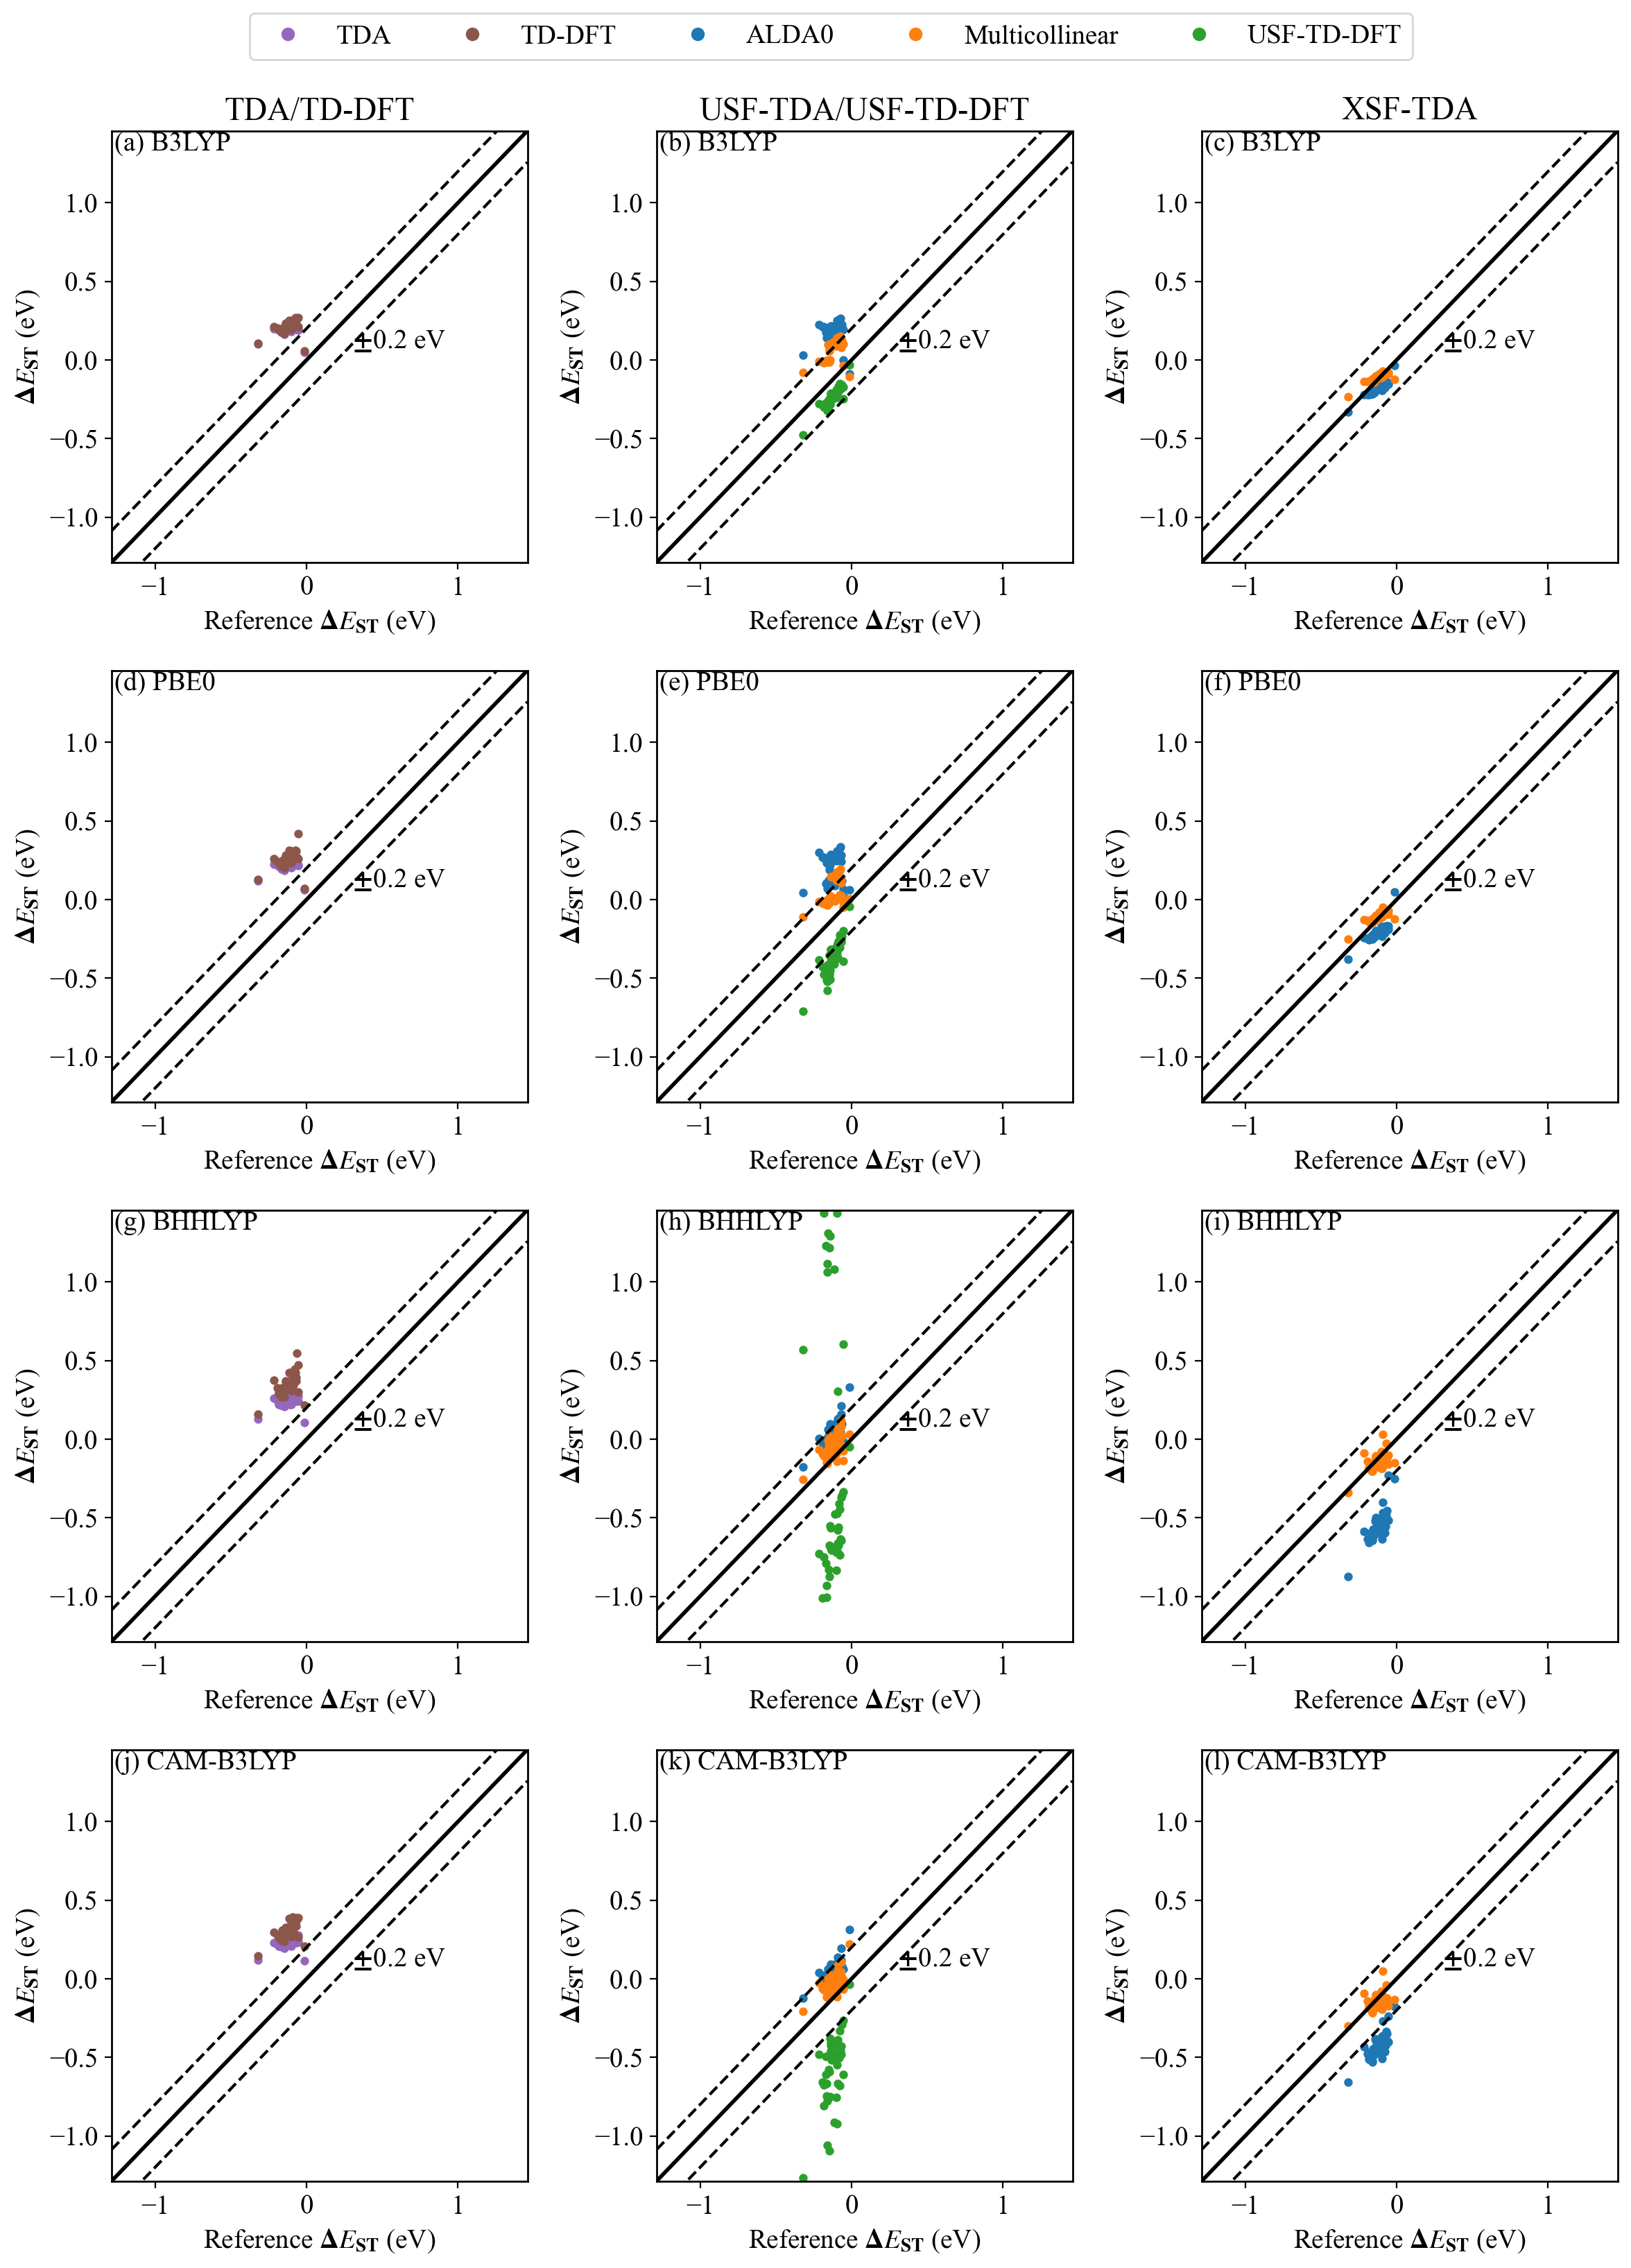

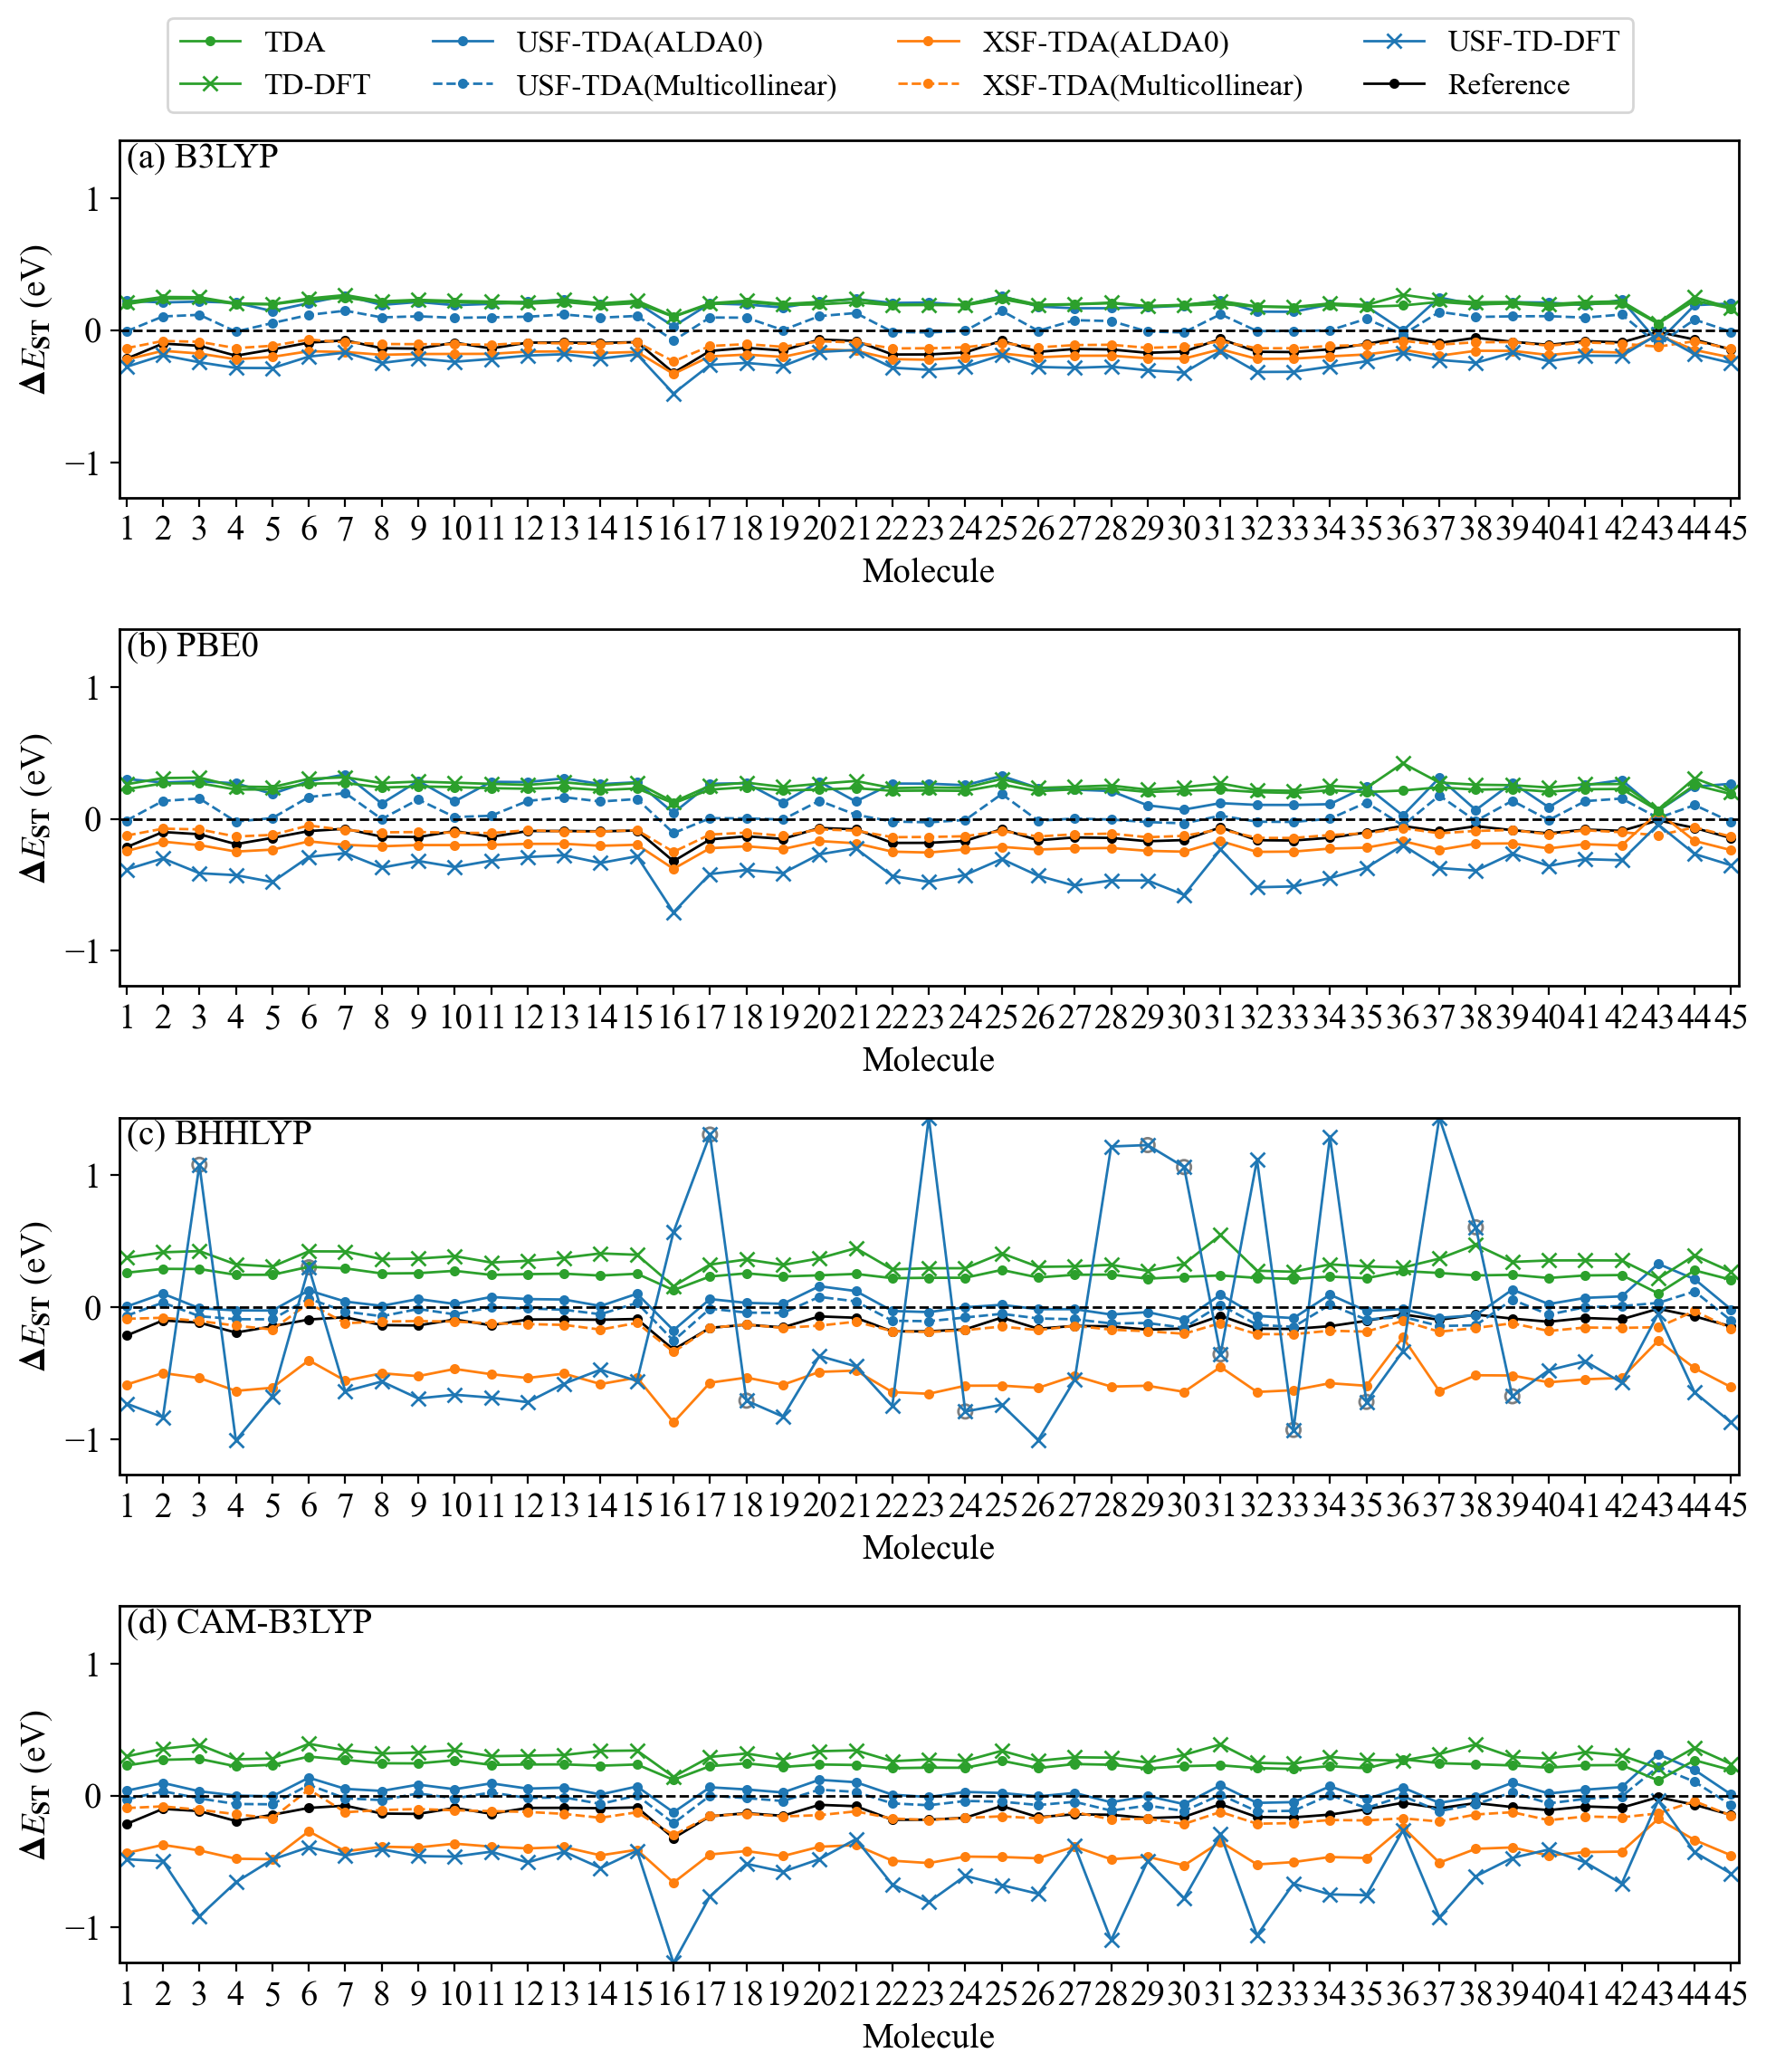

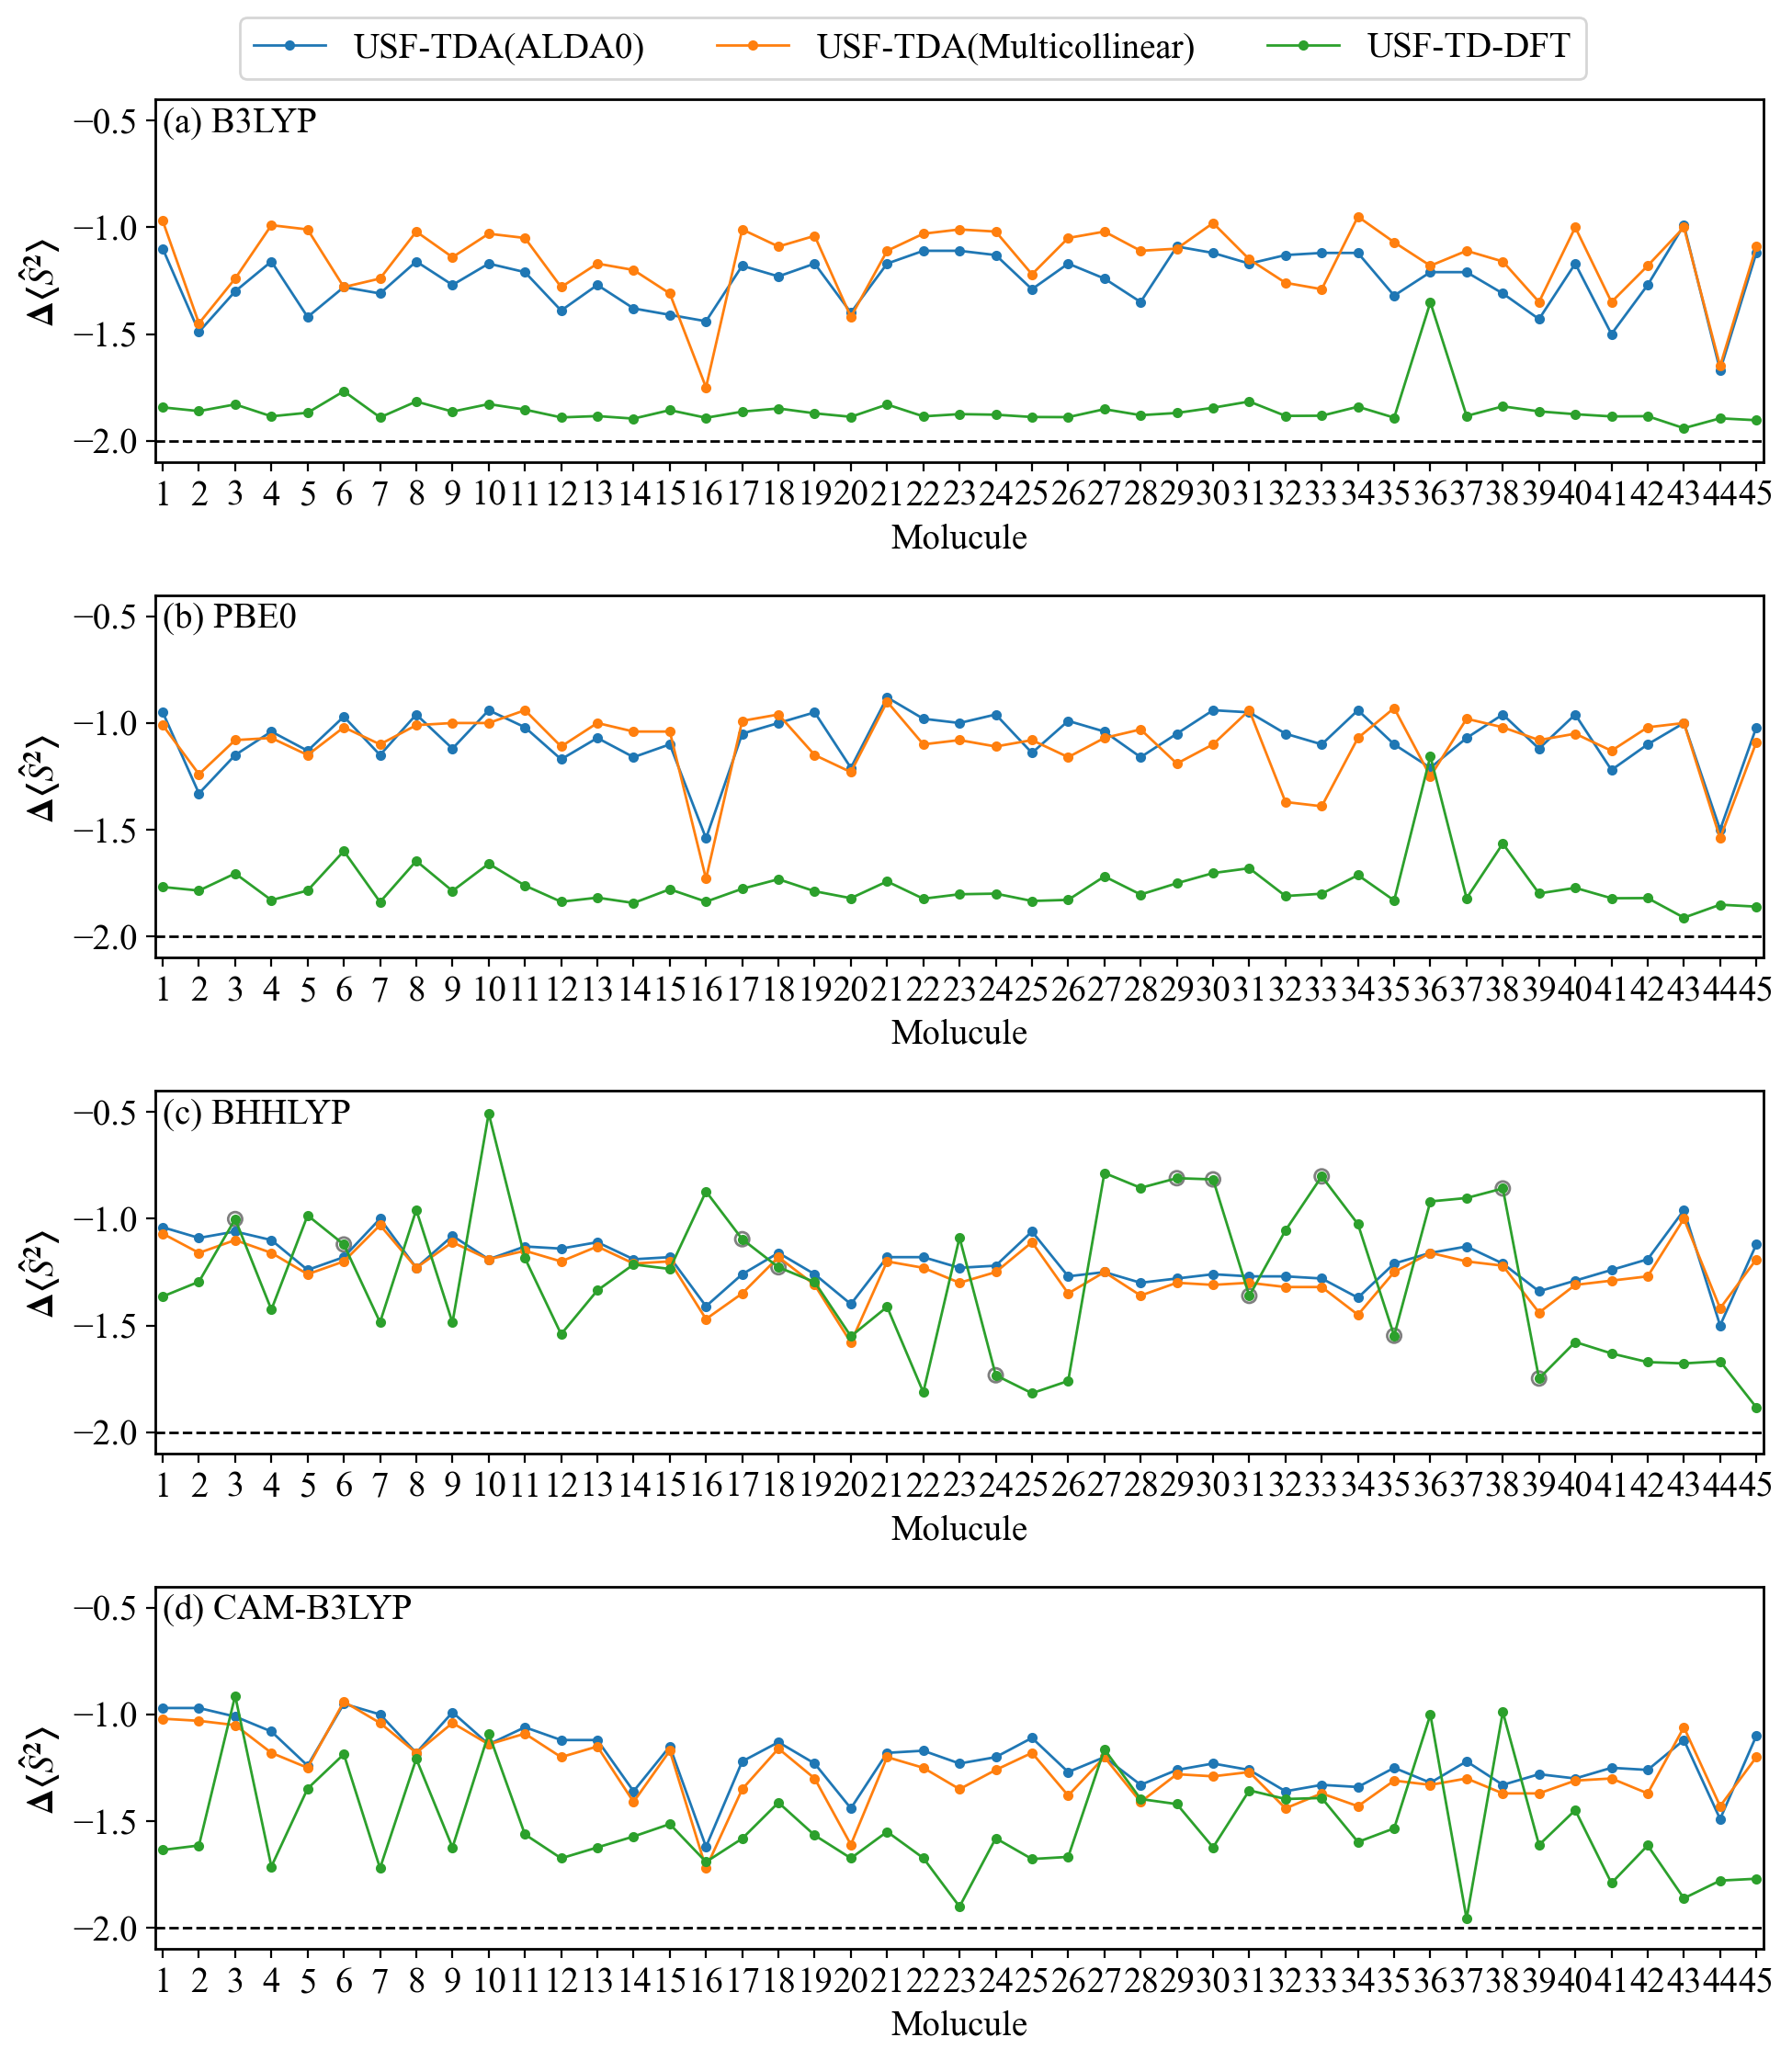

In [4]:
path = 'TADF_all.xlsx'

def Peng(path):
    ref,b3lyp_data,pbe0_data,bhhlyp_data,cam_data,ds2_data = read_xlsx(path,'Peng',45)
    b3lyp_tda,b3lyp_tddft,b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_usftddft,b3lyp_alda0_xsf,b3lyp_mc_xsf = b3lyp_data
    pbe0_tda,pbe0_tddft,pbe0_alda0_usf,pbe0_mc_usf,pbe0_usftddft,pbe0_alda0_xsf,pbe0_mc_xsf = pbe0_data
    bhhlyp_tda,bhhlyp_tddft,bhhlyp_alda0_usf,bhhlyp_mc_usf,bhhlyp_usftddft,bhhlyp_alda0_xsf,bhhlyp_mc_xsf = bhhlyp_data
    cam_tda,cam_tddft,cam_alda0_usf,cam_mc_usf,cam_usftddft,cam_alda0_xsf,cam_mc_xsf = cam_data
    ds2_b3lyp_usftddft,ds2_b3lyp_alda0,ds2_b3lyp_mc,ds2_pbe0_usftddft,ds2_pbe0_alda0,ds2_pbe0_mc, \
    ds2_bhhlyp_usftddft,ds2_bhhlyp_alda0,ds2_bhhlyp_mc,ds2_cam_usftddft,ds2_cam_alda0,ds2_cam_mc = ds2_data

    print('Statistical analysis ')
    print('B3LYP')
    calculate_error([ref,b3lyp_tda,b3lyp_tddft,b3lyp_usftddft,b3lyp_alda0_usf,b3lyp_alda0_xsf,b3lyp_mc_usf,b3lyp_mc_xsf],sign=1)
    print('PBE0')
    calculate_error([ref,pbe0_tda,pbe0_tddft,pbe0_usftddft,pbe0_alda0_usf,pbe0_alda0_xsf,pbe0_mc_usf,pbe0_mc_xsf],sign=1)
    print('BHHLYP')
    calculate_error([ref,bhhlyp_tda,bhhlyp_tddft,bhhlyp_usftddft,bhhlyp_alda0_usf,bhhlyp_alda0_xsf,bhhlyp_mc_usf,bhhlyp_mc_xsf],sign=1)
    print('CAM_B3LYP')
    calculate_error([ref,cam_tda,cam_tddft,cam_usftddft,cam_alda0_usf,cam_alda0_xsf,cam_mc_usf,cam_mc_xsf],sign=1)

    
    v_max = max(np.max(ref),np.max(b3lyp_data),np.max(pbe0_data),np.max(bhhlyp_data), np.max(cam_data))
    v_min = min(np.min(ref),np.min(b3lyp_data),np.min(pbe0_data),np.min(bhhlyp_data), np.min(cam_data))
    draw_scatter(ref,b3lyp_data,pbe0_data,bhhlyp_data,cam_data,v_max,v_min,'46ist_data2')

    x = np.arange(len(ref))+1
    fig,axs = plt.subplots(4,1,figsize=(10,11))
    x_data = [[b3lyp_alda0_usf,b3lyp_mc_usf,b3lyp_alda0_xsf,b3lyp_mc_xsf,b3lyp_tda,b3lyp_tddft,b3lyp_usftddft],
                  [pbe0_alda0_usf,pbe0_mc_usf,pbe0_alda0_xsf,pbe0_mc_xsf,pbe0_tda,pbe0_tddft,pbe0_usftddft],
                  [bhhlyp_alda0_usf,bhhlyp_mc_usf,bhhlyp_alda0_xsf,bhhlyp_mc_xsf,bhhlyp_tda,bhhlyp_tddft,bhhlyp_usftddft],
                  [cam_alda0_usf,cam_mc_usf,cam_alda0_xsf,cam_mc_xsf,cam_tda,cam_tddft,cam_usftddft]]
    x_data_label = ['(a) B3LYP','(b) PBE0','(c) BHHLYP', '(d) CAM-B3LYP']
    usftddft_im = [3,6,17,18,24,29,30,31,33,35,38,39]
    usftddft_im_v_bhhlyp = [bhhlyp_usftddft[i-1] for i in usftddft_im]
    for i in range(4):
        axs[i].plot(x,ref,label='Ref.',marker='.',color='black')
        axs[i].plot(x,x_data[i][0],label='USF-TDA(ALDA0)',marker='.',color='#1f77b4')
        axs[i].plot(x,x_data[i][1],label='USF-TDA(Multicollinear)',marker='.',linestyle='--',color='#1f77b4')
        axs[i].plot(x,x_data[i][2],label='XSF-TDA(ALDA0)',marker='.',color='#ff7f0e')
        axs[i].plot(x,x_data[i][3],label='XSF-TDA(Multicollinear)',marker='.',linestyle='--',color='#ff7f0e')
        axs[i].plot(x,x_data[i][4],label='TDA',marker='.',color='#2ca02c')
        axs[i].plot(x,x_data[i][5],label='TDDFT',marker='x',color='#2ca02c')
        axs[i].plot(x,x_data[i][6],label='USF-TD-DFT',marker='x',color='#1f77b4')
        if i == 2:
            axs[i].scatter(usftddft_im,usftddft_im_v_bhhlyp,marker='o',s=30,facecolors='none',edgecolors='#7f7f7f')
        axs[i].set_xticks(x,x)
        axs[i].set_ylabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
        axs[i].set_xlabel('Molecule')
        axs[i].set_xlim((0.8,x[-1]+0.2))
        axs[i].set_ylim((v_min,v_max))
        axs[i].text(1,v_max-0.2,f'{x_data_label[i]}')
        axs[i].axhline(y=0, color='black', linestyle='--', linewidth=1)
    legend_elements = [
            Line2D([0],[0],label='TDA',color='#2ca02c',marker='.'),
            Line2D([0],[0],label='TD-DFT',color='#2ca02c',marker='x'),
            Line2D([0], [0], label=r'USF-TDA(ALDA0)',color='#1f77b4',marker='.'),
            Line2D([0], [0], label=r'USF-TDA(Multicollinear)',color='#1f77b4',marker='.',linestyle='--'),
                   #markerfacecolor=blue, markersize=10),
            Line2D([0], [0],  label='XSF-TDA(ALDA0)',color='#ff7f0e',marker='.'),
                   #markerfacecolor=red, markersize=10),
            Line2D([0],[0],label='XSF-TDA(Multicollinear)',color='#ff7f0e',marker='.',linestyle='--'),
            Line2D([0],[0],label='USF-TD-DFT',color='#1f77b4',marker='x'),
            #Line2D([0],[0],label='ADC(2)',color='#8c564b',marker='.'),
            Line2D([0], [0],  label='Reference',color='black',marker='.')]
    fig.legend(
                handles=legend_elements,
                loc='upper center',
                bbox_to_anchor=(0.51, 1.05),  # 调整图例位置（y=1.05 表示在顶部上方）
                ncol=4,                      # 图例分 4 列显示
                #frameon=False,               # 去掉图例边框
                fontsize=12
            )
    plt.tight_layout()
    plt.savefig('46ist_data.pdf',bbox_inches='tight')
    plt.show()

    # \Delta S^{2}
    fig,axs = plt.subplots(4,1,figsize=(10,11))
    x = np.arange(len(ref))+1
    x_data = [[ds2_b3lyp_alda0,ds2_b3lyp_mc,ds2_b3lyp_usftddft],
                [ds2_pbe0_alda0,ds2_pbe0_mc,ds2_pbe0_usftddft],
                [ds2_bhhlyp_alda0,ds2_bhhlyp_mc,ds2_bhhlyp_usftddft],
                [ds2_cam_alda0,ds2_cam_mc,ds2_cam_usftddft]]
    x_data_label = ['(a) B3LYP','(b) PBE0','(c) BHHLYP','(d) CAM-B3LYP']
    ds2_bhhlyp_im = [ds2_bhhlyp_usftddft[i-1] for i in usftddft_im]
    for i in range(4):
        axs[i].plot(x,x_data[i][0],marker='.',label='USF-TDA(ALDA0)',color='#1f77b4')
        axs[i].plot(x,x_data[i][1],marker='.',label='USF-TDA(Multicollinear)',color='#ff7f0e')
        axs[i].plot(x,x_data[i][2],label='USF-TD-DFT',marker='.',color='#2ca02c')
        if i == 2:
            axs[i].scatter(usftddft_im,ds2_bhhlyp_im,marker='o',s=30,facecolors='none',edgecolors='#7f7f7f')
        axs[i].set_xlabel('Molucule')
        axs[i].set_xticks(x,x)
        axs[i].set_ylabel(r'$\Delta\langle \hat{S}^{2}\rangle$ ')
        axs[i].set_xlim((0.8,len(ref)+0.2))
        axs[i].set_ylim((-2.1,-0.4))
        axs[i].text(1,-0.55,f'{x_data_label[i]}')
        axs[i].axhline(y=-2,linestyle='--',color='black')

    legend_elements = [
            Line2D([0], [0], label=r'USF-TDA(ALDA0)',color='#1f77b4',marker='.'),
            Line2D([0], [0], label=r'USF-TDA(Multicollinear)',color='#ff7f0e',marker='.'),
            Line2D([0],[0],label='USF-TD-DFT',color='#2ca02c',marker='.')]
    fig.legend(
                handles=legend_elements,
                loc='upper center',
                bbox_to_anchor=(0.51, 1.03),  # 调整图例位置（y=1.05 表示在顶部上方）
                ncol=3,                      # 图例分 4 列显示
                #frameon=False,               # 去掉图例边框
                fontsize=14
            )
        
    plt.tight_layout()
    plt.savefig('46ist_ds2.pdf',bbox_inches='tight')
    plt.show()
    return None


Peng(path)
    
    

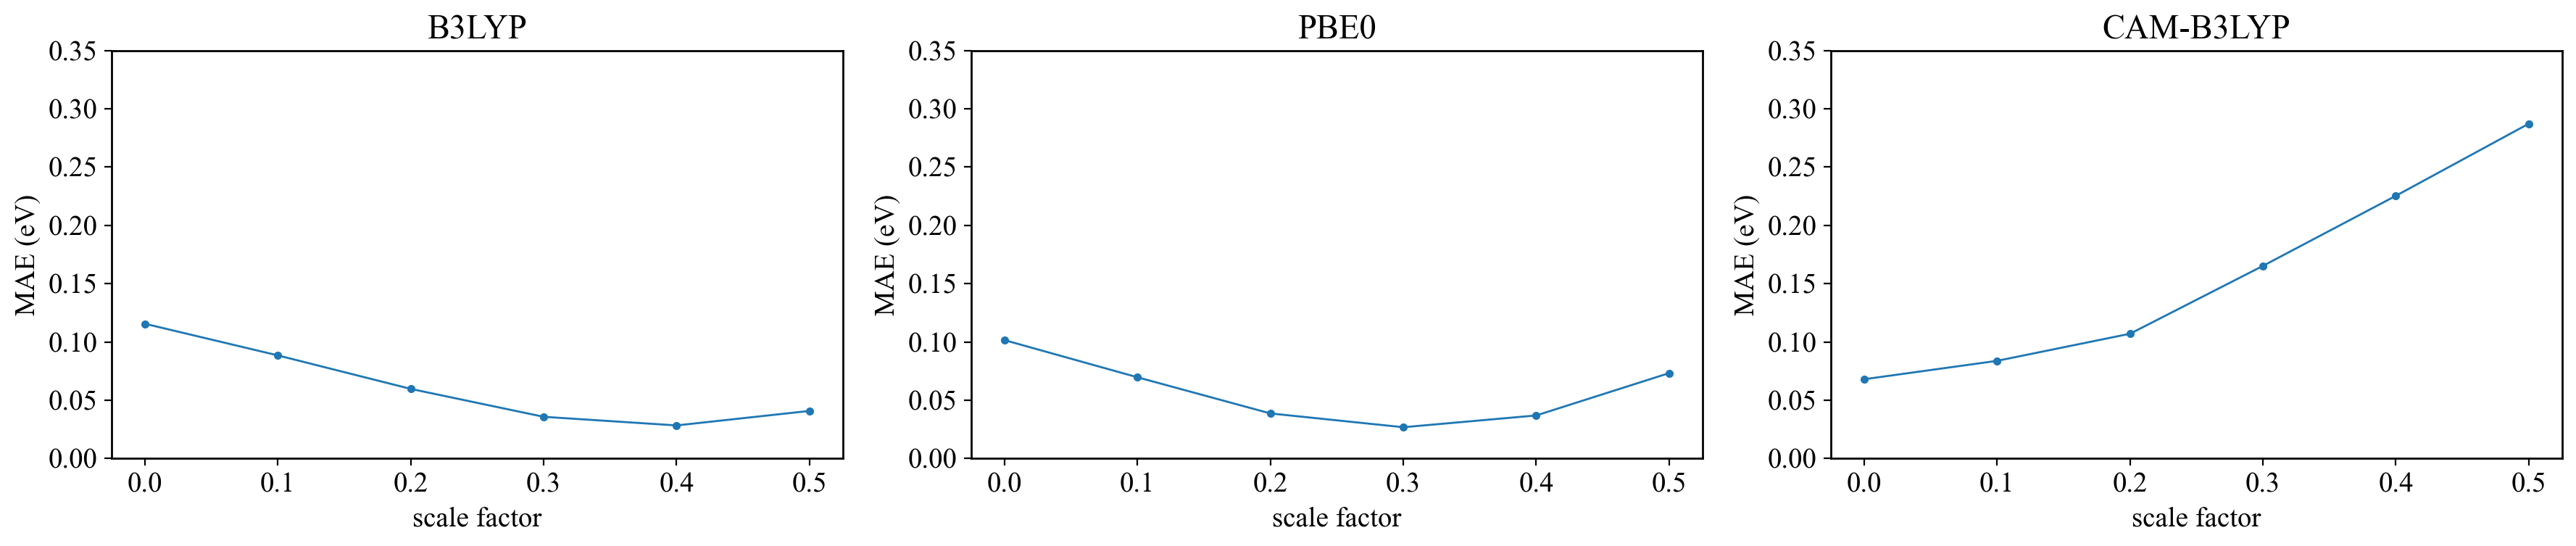

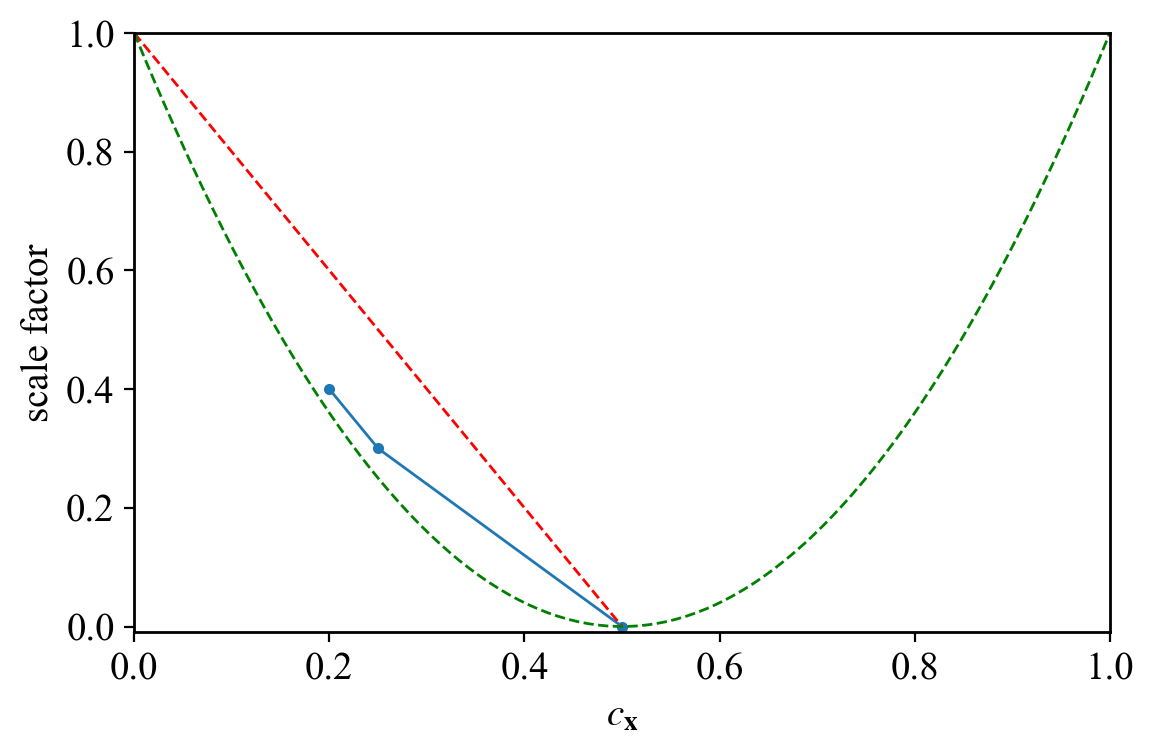

In [103]:
path = 'TADF_all.xlsx'

def calculate_mae(data):
    mae = []
    for i in range(len(data)-1):
        mae.append(np.mean(abs(data[i+1]-data[0])))
    return mae

def draw_Fig3(path):
    f = pd.ExcelFile(path)
    data = f.parse('Fig3')
    ref = np.array(data.iloc[2:,1][:10])
    b3lyp_0 = np.array(data.iloc[2:,2][:10])
    b3lyp_1 = np.array(data.iloc[2:,3][:10])
    b3lyp_2 = np.array(data.iloc[2:,4][:10])
    b3lyp_3 = np.array(data.iloc[2:,5][:10])
    b3lyp_4 = np.array(data.iloc[2:,6][:10])
    b3lyp_5 = np.array(data.iloc[2:,7][:10])

    pbe0_0 = np.array(data.iloc[2:,9][:10])
    pbe0_1 = np.array(data.iloc[2:,10][:10])
    pbe0_2 = np.array(data.iloc[2:,11][:10])
    pbe0_3 = np.array(data.iloc[2:,12][:10])
    pbe0_4 = np.array(data.iloc[2:,13][:10])
    pbe0_5 = np.array(data.iloc[2:,14][:10])

    cam_0 = np.array(data.iloc[2:,16][:10])
    cam_1 = np.array(data.iloc[2:,17][:10])
    cam_2 = np.array(data.iloc[2:,18][:10])
    cam_3 = np.array(data.iloc[2:,19][:10])
    cam_4 = np.array(data.iloc[2:,20][:10])
    cam_5 = np.array(data.iloc[2:,21][:10])
   
    b3lyp_mae = calculate_mae([ref,b3lyp_0,b3lyp_1,b3lyp_2,b3lyp_3,b3lyp_4,b3lyp_5])
    pbe0_mae = calculate_mae([ref,pbe0_0,pbe0_1,pbe0_2,pbe0_3,pbe0_4,pbe0_5])
    cam_mae = calculate_mae([ref,cam_0,cam_1,cam_2,cam_3,cam_4,cam_5])

    s = np.arange(6)*0.1
    s_data = [b3lyp_mae,pbe0_mae,cam_mae]
    s_data_label = ['B3LYP','PBE0','CAM-B3LYP']

    fig,axs = plt.subplots(1,3,figsize=(18,4))
    for i in range(3):
        axs[i].plot(s,s_data[i],marker='.',color='#1f77b4')
        axs[i].set_title(f'{s_data_label[i]}')
        axs[i].set_xlabel('scale factor')
        axs[i].set_ylabel(r'MAE (eV)')
        axs[i].set_ylim((0.00,0.35))
    plt.tight_layout()
    plt.savefig('mc_scale.pdf')
    plt.show()

    fx = [0.4,0.3,0] # optimal s for B3LYP PBE0 BHHLYP
    x = [0.2,0.25,0.5] # c_X
    x0 = np.linspace(0.0, 1.0, 100) # line
    y = 4 * (x0 - 0.5)**2 # quadratic 

    fig,axs = plt.subplots(1,1,figsize=(6,4))
    axs.plot(x,fx,marker='.')
    axs.set_ylim((-0.01,1))
    axs.set_xlim((0,1))
    axs.plot([0,0.5],[1,0],'r--')
    axs.plot(x0,y,color='green',linestyle='--')

    axs.set_xlabel(r'$c_{\mathrm{x}}$')
    axs.set_ylabel('scale factor')

    plt.tight_layout()
    plt.savefig('mc_scale_cx.pdf')

    return None

draw_Fig3(path)

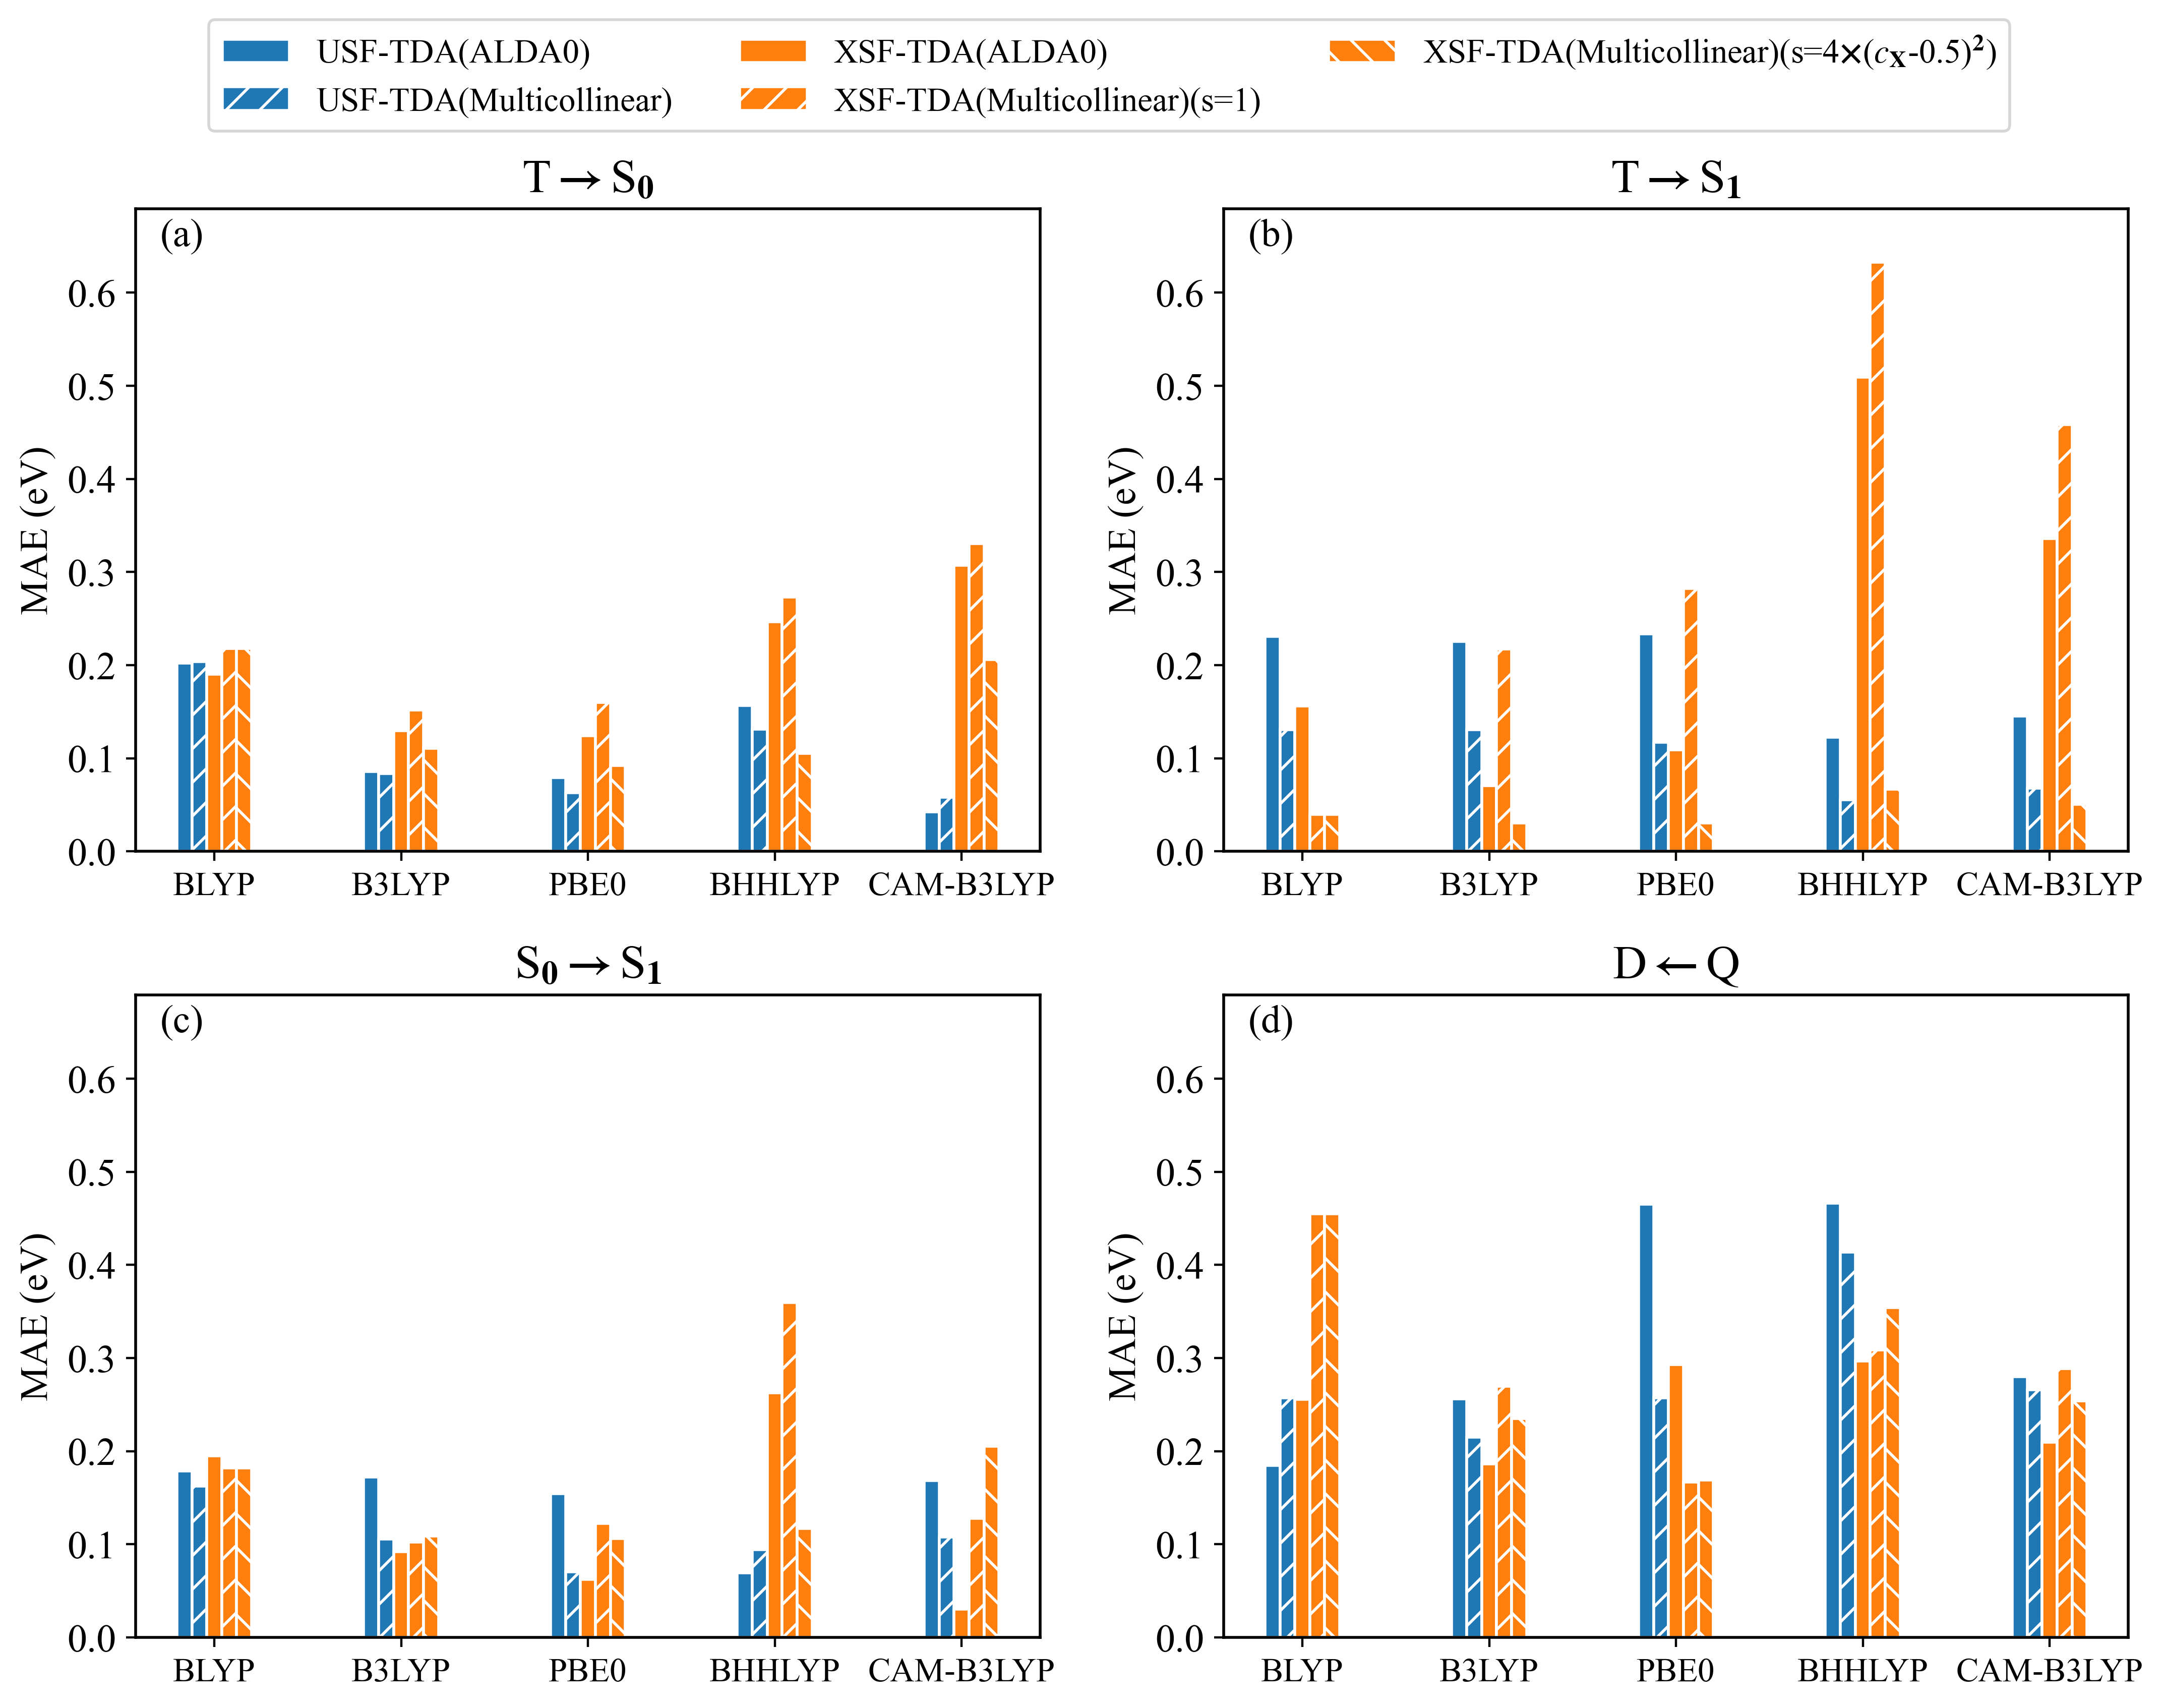

In [108]:
path = 'TADF_all.xlsx'

def calculate_mae(ref,data):
    mae = []
    for i in range(len(data)):
        mae.append(np.mean(abs(data[i]-ref)))
    return mae


def read_Fig5_loos(path,start,nums):
    f = pd.ExcelFile(path)
    data = f.parse('Fig5')
    ref = np.array(data.iloc[start:,1][:nums])
    alda0_usf_blyp = np.array(data.iloc[start:,2][:nums])
    alda0_usf_b3lyp = np.array(data.iloc[start:,3][:nums])
    alda0_usf_pbe0 = np.array(data.iloc[start:,4][:nums])
    alda0_usf_bhhlyp = np.array(data.iloc[start:,5][:nums])
    alda0_usf_cam = np.array(data.iloc[start:,6][:nums])
    alda0_usf = np.array([alda0_usf_blyp,alda0_usf_b3lyp,alda0_usf_pbe0,alda0_usf_bhhlyp,alda0_usf_cam])
    

    mc_usf_blyp = np.array(data.iloc[start:,8][:nums])
    mc_usf_b3lyp = np.array(data.iloc[start:,9][:nums])
    mc_usf_pbe0 = np.array(data.iloc[start:,10][:nums])
    mc_usf_bhhlyp = np.array(data.iloc[start:,11][:nums])
    mc_usf_cam = np.array(data.iloc[start:,12][:nums])
    mc_usf = np.array([mc_usf_blyp,mc_usf_b3lyp,mc_usf_pbe0,mc_usf_bhhlyp,mc_usf_cam])

    alda0_xsf_blyp = np.array(data.iloc[start:,14][:nums])
    alda0_xsf_b3lyp = np.array(data.iloc[start:,15][:nums])
    alda0_xsf_pbe0 = np.array(data.iloc[start:,16][:nums])
    alda0_xsf_bhhlyp = np.array(data.iloc[start:,17][:nums])
    alda0_xsf_cam = np.array(data.iloc[start:,18][:nums])
    alda0_xsf = np.array([alda0_xsf_blyp,alda0_xsf_b3lyp,alda0_xsf_pbe0,alda0_xsf_bhhlyp,alda0_xsf_cam])

    mc_xsf1_blyp = np.array(data.iloc[start:,20][:nums])  # Multicollinear has two approach
    mc_xsf1_b3lyp = np.array(data.iloc[start:,21][:nums])
    mc_xsf1_pbe0 = np.array(data.iloc[start:,22][:nums])
    mc_xsf1_bhhlyp = np.array(data.iloc[start:,23][:nums])
    mc_xsf1_cam = np.array(data.iloc[start:,24][:nums])
    mc_xsf1 = np.array([mc_xsf1_blyp,mc_xsf1_b3lyp,mc_xsf1_pbe0,mc_xsf1_bhhlyp,mc_xsf1_cam])

    mc_xsf2_blyp = np.array(data.iloc[start:,26][:nums])  
    mc_xsf2_b3lyp = np.array(data.iloc[start:,27][:nums])
    mc_xsf2_pbe0 = np.array(data.iloc[start:,28][:nums])
    mc_xsf2_bhhlyp = np.array(data.iloc[start:,29][:nums])
    mc_xsf2_cam = np.array(data.iloc[start:,30][:nums])
    mc_xsf2 = np.array([mc_xsf2_blyp,mc_xsf2_b3lyp,mc_xsf2_pbe0,mc_xsf2_bhhlyp,mc_xsf2_cam])

    return ref,alda0_usf,mc_usf,alda0_xsf,mc_xsf1,mc_xsf2
    


def draw_Fig5(path):
    # read triplet, singlet excited energies for Loos data
    ref_t,alda0_usf_t,mc_usf_t,alda0_xsf_t,mc_xsf1_t,mc_xsf2_t= read_Fig5_loos(path,1,10) 
    ref_s,alda0_usf_s,mc_usf_s,alda0_xsf_s,mc_xsf1_s,mc_xsf2_s= read_Fig5_loos(path,15,10) 
    ref_st = ref_s - ref_t
    alda0_usf_st = alda0_usf_s - alda0_usf_t
    mc_usf_st = mc_usf_s - mc_usf_t
    alda0_xsf_st = alda0_xsf_s - alda0_xsf_t
    mc_xsf1_st = mc_xsf1_s - mc_xsf1_t
    mc_xsf2_st = mc_xsf2_s - mc_xsf2_t

    alda0_usf_t_mae = calculate_mae(ref_t,alda0_usf_t)
    alda0_usf_s_mae = calculate_mae(ref_s,alda0_usf_s)
    alda0_usf_st_mae = calculate_mae(ref_st,alda0_usf_st)
    mc_usf_t_mae = calculate_mae(ref_t,mc_usf_t)
    mc_usf_s_mae = calculate_mae(ref_s,mc_usf_s)
    mc_usf_st_mae = calculate_mae(ref_st,mc_usf_st)
    alda0_xsf_t_mae = calculate_mae(ref_t,alda0_xsf_t)
    alda0_xsf_s_mae = calculate_mae(ref_s,alda0_xsf_s)
    alda0_xsf_st_mae = calculate_mae(ref_st,alda0_xsf_st)
    mc_xsf1_t_mae = calculate_mae(ref_t,mc_xsf1_t)
    mc_xsf1_s_mae = calculate_mae(ref_s,mc_xsf1_s)
    mc_xsf1_st_mae = calculate_mae(ref_st,mc_xsf1_st)
    mc_xsf2_t_mae = calculate_mae(ref_t,mc_xsf2_t)
    mc_xsf2_s_mae = calculate_mae(ref_s,mc_xsf2_s)
    mc_xsf2_st_mae = calculate_mae(ref_st,mc_xsf2_st)

    ref_q,alda0_usf_q,mc_usf_q,alda0_xsf_q,mc_xsf1_q,mc_xsf2_q= read_Fig5_loos(path,43,19)
    alda0_usf_q_mae = calculate_mae(ref_q,alda0_usf_q)
    mc_usf_q_mae = calculate_mae(ref_q,mc_usf_q)
    alda0_xsf_q_mae = calculate_mae(ref_q,alda0_xsf_q)
    mc_xsf1_q_mae = calculate_mae(ref_q,mc_xsf1_q)
    mc_xsf2_q_mae = calculate_mae(ref_q,mc_xsf2_q)

    funs = ['BLYP','B3LYP','PBE0','BHHLYP','CAM-B3LYP']
    x = np.arange(len(funs))
    width = 0.08
    fig, axs = plt.subplots(2,2,figsize=(11, 8), dpi=200)
    all_data = [[alda0_usf_t_mae,mc_usf_t_mae,alda0_xsf_t_mae,mc_xsf1_t_mae,mc_xsf2_t_mae],
                [alda0_usf_st_mae,mc_usf_st_mae,alda0_xsf_st_mae,mc_xsf1_st_mae,mc_xsf2_st_mae],
                [alda0_usf_s_mae,mc_usf_s_mae,alda0_xsf_s_mae,mc_xsf1_s_mae,mc_xsf2_s_mae],
                [alda0_usf_q_mae,mc_usf_q_mae,alda0_xsf_q_mae,mc_xsf1_q_mae,mc_xsf2_q_mae]]
    count = 0
    for i in range(2):
        for j in range(2):
            axs[i,j].bar(x-2*width,all_data[count][0],width,label=r'USF-TDA(ALDA0)',edgecolor='white',color='#1f77b4')
            axs[i,j].bar(x-1*width,all_data[count][1],width,label=r'USF-TDA(multicollinear)',edgecolor='white',color='#1f77b4',hatch='//')
            axs[i,j].bar(x,all_data[count][2],width,label=r'XSF-TDA(ALDA0)',edgecolor='white',color='#ff7f0e')
            axs[i,j].bar(x+width,all_data[count][3],width,label=r'XSF-TDA(multicollinear)(s=1)',edgecolor='white',color='#ff7f0e',hatch='//')
            axs[i,j].bar(x+2*width,all_data[count][4],width,label=r'XSF-TDA(multicollinear)(s=4$\times$($c_{\mathrm{X}}$-0.5)$^2$)',edgecolor='white',color='#ff7f0e',hatch='\\\\')
            if count == 0:
                axs[i,j].set_title(r'T$\to$S$_0$')
                axs[i,j].text(-0.29,0.65,'(a)')
            elif count == 1:
                axs[i,j].set_title(r'T$\to$S$_1$')
                axs[i,j].text(-0.29,0.65,'(b)')
            elif count == 2:
                axs[i,j].set_title(r'S$_0 \to$S$_1$')
                axs[i,j].text(-0.29,0.65,'(c)')
            elif count == 3:
                axs[1,1].set_title(r'D$\leftarrow$Q')
                axs[i,j].text(-0.29,0.65,'(d)')
            axs[i,j].set_xticks(x)
            axs[i,j].set_xticklabels(funs, fontsize=12)
            axs[i,j].set_ylabel('MAE (eV)')
            axs[i,j].set_ylim((0,0.69))
            count += 1
    legend_elements = [
        Patch(label=r'USF-TDA(ALDA0)',facecolor='#1f77b4',edgecolor='white'),
        Patch(label=r'USF-TDA(Multicollinear)',facecolor='#1f77b4',hatch='//',edgecolor='white'),
        Patch(label='XSF-TDA(ALDA0)',facecolor='#ff7f0e',edgecolor='white'),
        Patch(label='XSF-TDA(Multicollinear)(s=1)',facecolor='#ff7f0e',hatch='//',edgecolor='white'),
        Patch(label=r'XSF-TDA(Multicollinear)(s=4$\times$($c_{\mathrm{X}}$-0.5)$^2$)',facecolor='#ff7f0e',
              hatch='\\\\',edgecolor='white')]
    fig.legend(
            handles=legend_elements,
            loc='upper center',
            bbox_to_anchor=(0.51, 1.07),  # 调整图例位置（y=1.05 表示在顶部上方）
            ncol=3,                      # 图例分 4 列显示
            #frameon=False,               # 去掉图例边框
            fontsize=12
        )
    plt.tight_layout()
    plt.savefig('xsf_multicollinear.pdf',bbox_inches='tight')
    plt.show()

    return None


draw_Fig5(path)

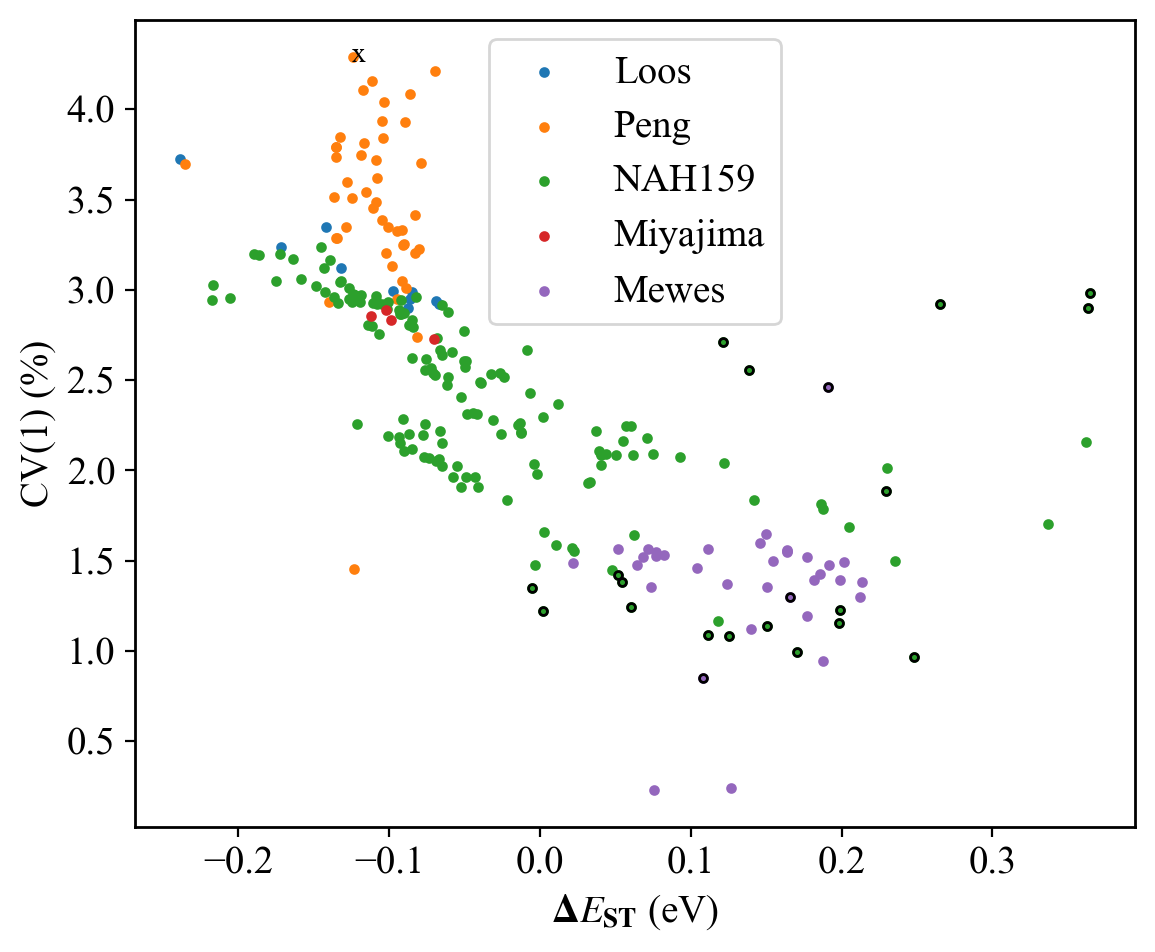

In [5]:
# CV1
path = 'TADF_all.xlsx'

def read_cv_oo(path,keys,nums):
    f = pd.ExcelFile(path)
    data = f.parse(keys)
    e = np.array(data.iloc[2:,8][:nums])
    cv = np.array(data.iloc[2:,35][:nums])
    oo = np.array(data.iloc[2:,56][:nums])
    return e,cv,oo
    

def draw_cv1(path): # CV1 in XSF-TDA/B3LYP/multicollinear
    f = pd.ExcelFile(path)
    data = f.parse('Fig5')
    loos_e = np.array(data.iloc[29:,27][:10])
    loos_cv = np.array(data.iloc[29:,32][:10]) # OO1 > 90%
    peng_e,peng_cv,_ = read_cv_oo(path,'Peng',45) # OO1 > 50%
    nah159_e,nah159_cv,nah159_oo = read_cv_oo(path,'NAH159',159) # OO1 may less than 50%
    Miyajima_e,Miyajima_cv,_ = read_cv_oo(path,'Miyajima',4) # OO1 > 50%
    mr_tadf_e,mr_tadf_cv,mr_tadf_oo = read_cv_oo(path,'MR-TADF',35) # 001 may less than 50%

    nah159_e_2 = [nah159_e[i] for i in range(len(nah159_e)) if nah159_oo[i]<=0.5]
    nah159_cv_2 = [nah159_cv[i] for i in range(len(nah159_e)) if nah159_oo[i]<=0.5]
    mr_tadf_e_2 = [mr_tadf_e[i] for i in range(len(mr_tadf_e)) if mr_tadf_oo[i]<=0.5]
    mr_tadf_cv_2 = [mr_tadf_cv[i] for i in range(len(mr_tadf_e)) if mr_tadf_oo[i]<=0.5]

    fig,axs = plt.subplots(1,1,figsize=(6,5))
    axs.scatter(loos_e,loos_cv,s=8,label='Loos',color='#1f77b4')
    axs.scatter(peng_e,peng_cv,s=8,label='Peng',color='#ff7f0e')
    axs.scatter(nah159_e,nah159_cv,s=8,label='NAH159',color='#2ca02c')
    axs.scatter(Miyajima_e,Miyajima_cv,s=8,label='Miyajima',color='#d62728')
    axs.scatter(mr_tadf_e,mr_tadf_cv,s=8,label='Mewes',color='#9467bd')

    axs.scatter(nah159_e_2,nah159_cv_2,s=8,color='#2ca02c',edgecolors='black')
    axs.scatter(mr_tadf_e_2,mr_tadf_cv_2,s=8,color='#9467bd',edgecolors='black')


    axs.text(-0.125,max(peng_cv)-0.03,'x',fontsize=10)
    axs.set_xlabel(r'$\Delta E_{\mathrm{ST}}$ (eV)')
    axs.set_ylabel('CV(1) (%)')

    plt.legend()
    plt.tight_layout()
    plt.savefig('xsf_cv.pdf')
    plt.show()

    return None

draw_cv1(path)

In [7]:
# all in bar
path = 'TADF_all.xlsx'

def calculate_mae(ref,data):
    new_data = [data[i] for i in [2,3,5,6]] # only usf(alda0 mc), xsf(alda0,mc)
    mae = []
    error = []
    for i in range(4):
        error.append(new_data[i]-ref)
        mae.append(np.mean(abs(new_data[i]-ref)))
    return np.array(mae),np.array(error)


def all_in_bar(path):
    plt.rcParams['axes.spines.top'] = False
    plt.rcParams['axes.spines.right'] = False
    plt.rcParams['axes.spines.left'] = True
    plt.rcParams['axes.spines.bottom'] = True
    plt.rcParams['axes.linewidth'] = 0.8  # 坐标轴线宽
    plt.rcParams['axes.edgecolor'] = 'black'  # 坐标轴颜色
    plt.rcParams['xtick.direction'] = 'in'  # 刻度向内
    plt.rcParams['ytick.direction'] = 'in'
    plt.rcParams['xtick.major.width'] = 0.8  # 主刻度线宽
    plt.rcParams['ytick.major.width'] = 0.8
    plt.rcParams['xtick.minor.width'] = 0.5  # 次刻度线宽
    plt.rcParams['ytick.minor.width'] = 0.5


    # read data
    ref,nah159_b3lyp_data,nah159_pbe0_data,nah159_bhhlyp_data,nah159_cam_data,_ = read_xlsx(path,'NAH159',159)
    nah159_b3lyp_mae,nah159_b3lyp_err = calculate_mae(ref,nah159_b3lyp_data)
    nah159_pbe0_mae,nah159_pbe0_err = calculate_mae(ref,nah159_pbe0_data)
    nah159_bhhlyp_mae,nah159_bhhlyp_err = calculate_mae(ref,nah159_bhhlyp_data)
    nah159_cam_mae,nah159_cam_err = calculate_mae(ref,nah159_cam_data)
    ref,mr_tadf_b3lyp_data,mr_tadf_pbe0_data,mr_tadf_bhhlyp_data,mr_tadf_cam_data,_ = read_xlsx(path,'MR-TADF',35)
    mr_tadf_b3lyp_mae,mr_tadf_b3lyp_err = calculate_mae(ref,mr_tadf_b3lyp_data)
    mr_tadf_pbe0_mae,mr_tadf_pbe0_err = calculate_mae(ref,mr_tadf_pbe0_data)
    mr_tadf_bhhlyp_mae,mr_tadf_bhhlyp_err = calculate_mae(ref,mr_tadf_bhhlyp_data)
    mr_tadf_cam_mae,mr_tadf_cam_err = calculate_mae(ref,mr_tadf_cam_data)
    ref,miyajima_b3lyp_data,miyajima_pbe0_data,miyajima_bhhlyp_data,miyajima_cam_data,_ = read_xlsx(path,'Miyajima',4)
    miyajima_b3lyp_mae,miyajima_b3lyp_err = calculate_mae(ref,miyajima_b3lyp_data)
    miyajima_pbe0_mae,miyajima_pbe0_err = calculate_mae(ref,miyajima_pbe0_data)
    miyajima_bhhlyp_mae,miyajima_bhhlyp_err = calculate_mae(ref,miyajima_bhhlyp_data)
    miyajima_cam_mae,miyajima_cam_err = calculate_mae(ref,miyajima_cam_data)
    ref,peng_b3lyp_data,peng_pbe0_data,peng_bhhlyp_data,peng_cam_data,_ = read_xlsx(path,'Peng',45)
    peng_b3lyp_mae,peng_b3lyp_err = calculate_mae(ref,peng_b3lyp_data)
    peng_pbe0_mae,peng_pbe0_err = calculate_mae(ref,peng_pbe0_data)
    peng_bhhlyp_mae,peng_bhhlyp_err = calculate_mae(ref,peng_bhhlyp_data)
    peng_cam_mae,peng_cam_err = calculate_mae(ref,peng_cam_data)

    min_error = -0.115
    max_error = 0.437
    bin_width = 0.05
    bins = np.arange(-0.7-bin_width, 0.7 + bin_width, bin_width)
    count = 0
    labs = ['a','b','c','d','e','f','g','h','i','j','k','l','m','n','o','p','q','r','s','t'] 
    nah159_err = np.array([nah159_b3lyp_err,nah159_pbe0_err,nah159_bhhlyp_err,nah159_cam_err]).reshape(-1,159)
    mr_tadf_err = np.array([mr_tadf_b3lyp_err,mr_tadf_pbe0_err,mr_tadf_bhhlyp_err,mr_tadf_cam_err]).reshape(-1,35)
    miyajima_err = np.array([miyajima_b3lyp_err,miyajima_pbe0_err,miyajima_bhhlyp_err,miyajima_cam_err]).reshape(-1,4)
    peng_err = np.array([peng_b3lyp_err,peng_pbe0_err,peng_bhhlyp_err,peng_cam_err]).reshape(-1,45)

    fig, axs = plt.subplots(4,4,figsize=(16, 24), dpi=200)
    for i,ax in enumerate(axs.flat):
        lab = labs[i]
        nah159_error = nah159_err[count]
        mr_tadf_error = mr_tadf_err[count]
        miyajima_error = miyajima_err[count]
        peng_error = peng_err[count]
        max_counts = 56
        mae = np.mean([np.mean(abs(nah159_error)), np.mean(abs(miyajima_error)),np.mean(abs(peng_error)),
                           np.mean(abs(mr_tadf_error))]) 
        seaborn.histplot(data=nah159_error,bins=bins,ax=ax,edgecolor='black', alpha=0.5,color='#1f77b4',kde=True,line_kws={"lw": 2.5, "alpha": 1})
        seaborn.histplot(data=peng_error,bins=bins,ax=ax,edgecolor='black', alpha=0.5,color='#ff7f0e',kde=True,line_kws={"lw": 2.5, "alpha": 1})
        seaborn.histplot(data=mr_tadf_error,bins=bins,ax=ax,edgecolor='black', alpha=0.5,color='#2ca02c',kde=True,line_kws={"lw": 2.5, "alpha": 1})
        seaborn.histplot(data=miyajima_error,bins=bins,ax=ax,edgecolor='black', alpha=0.5,color='#9467bd',kde=True,line_kws={"lw": 2.5, "alpha": 1})
        ax.text(0.1,50,f'MAE:{mae:.3f} eV',fontsize=18)
        ax.text(-0.2,55,f'({lab})')
        if i == 0:
            ax.text(-0.43,60,'USF-TDA(ALDA0)',fontsize=18)
            ax.text(-0.75,35,'B3LYP',fontsize=18)
        elif i == 1:
            ax.text(-0.43,60,'USF-TDA(multicollinear)',fontsize=18)
        elif i == 2:
            ax.text(-0.43,60,'XSF-TDA(ALDA0)',fontsize=18)
        elif i == 3:
            ax.text(-0.43,60,'XSF-TDA(multicollinear)',fontsize=18)
        elif i == 4:
            ax.text(-0.75,35,'PBE0',fontsize=18)
        elif i == 8:
            ax.text(-0.75,35,'BHHLYP',fontsize=18)
        elif i == 12:
            ax.text(-0.75,35,'CAM-BHHLYP',fontsize=18)

        ax.spines['left'].set_position(('data', 0))  # y in x=0


        x_lim = max(min_error,max_error)
        ax.set_xlim(-0.75,0.75)  
        ax.set_ylim(0,max_counts+2)
        ax.xaxis.set_major_locator(MultipleLocator(0.25))
        ax.xaxis.set_minor_locator(MultipleLocator(0.05))
        ax.yaxis.set_major_locator(MultipleLocator(max_counts/5))
        ax.tick_params(axis='x', which='major', length=4, width=0.5, direction='in')
        ax.tick_params(axis='x', which='minor', length=2, width=0.3, direction='in')
        ax.tick_params(axis='y', which='major', length=4, width=0.5, direction='in')
        ax.tick_params(axis='y', which='minor', length=2, width=0.3, direction='in')
        ax.tick_params(axis='x', labelsize=14)
        ax.set_xlabel('Error (eV)')
        ax.set_ylabel('')

        y_ticks = np.arange(0, max_counts + 1, 10)  
        ax.tick_params(axis='y', labelsize=14)
        ax.set_yticks(y_ticks[1:])
        ax.spines['left'].set_visible(True)
        count += 1
        
    legend_elements = [
            Line2D([0], [0], label=r'NAH159',color='#1f77b4',alpha=0.5,marker='s',linestyle=''),
            Line2D([0], [0],  label='Mewes',color='#2ca02c',marker='s',linestyle='',alpha=0.5),
            Line2D([0],[0],label='Miyajima',color='#9467bd',marker='s',linestyle='',alpha=0.5),
            Line2D([0], [0], label=r'Peng',color='#ff7f0e',marker='s',linestyle='',alpha=0.5),         
        ]
    leg = 1
    if leg:
        fig.legend(
            handles=legend_elements,
            loc='upper center',
            bbox_to_anchor=(0.51, 1.03),  # 调整图例位置（y=1.05 表示在顶部上方）
            ncol=5,                      # 图例分 4 列显示
            #frameon=False,               # 去掉图例边框
            fontsize=16
        )
    
    plt.tight_layout()
    plt.savefig('all_in_bar.pdf',bbox_inches='tight')
    plt.show()


    return None

all_in_bar(path)
    